Your task is to build mathematical models
that can predict bicycle traffic volume from weather and calendar features.

# Project Tasks

In [95]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os
import sklearn

## Data Split

Split your data into train/validation/test sets. For example, you can split them chronologically and train on 01-01-2021 to 30-06-2022, validate on 01-07-2022 to 31-12-2022, and hold out 2023 as the final test set.

In [96]:
weather = pd.read_csv(
    "./bike_project_data/weather_copenhagen.csv", parse_dates=["datetime"]
)
holidays = pd.read_csv("./bike_project_data/danish_holidays.csv", parse_dates=["date"])
stations = pd.read_csv("./bike_project_data/stations.csv")
bike_counts = pd.read_csv(
    "./bike_project_data/bike_counts.csv", parse_dates=["datetime"]
)

In [97]:
# load the data

# print dates ranges for weather
print(
    f"Weather data ranges from {weather['datetime'].min()} to {weather['datetime'].max()}"
)

Weather data ranges from 2021-01-01 00:00:00 to 2023-12-31 23:00:00


In [98]:
# split into train / test by date: 2021-01-01 to 2022-12-31 for training, 2023-01-01 to 2023-12-31 for testing
train_start_date = pd.to_datetime("2021-01-01")
train_end_date = pd.to_datetime("2022-12-31")
test_start_date = pd.to_datetime("2023-01-01")
test_end_date = pd.to_datetime("2023-12-31")

train_bike_counts = bike_counts[
    (bike_counts["datetime"] >= train_start_date)
    & (bike_counts["datetime"] <= train_end_date)
]
test_bike_counts = bike_counts[
    (bike_counts["datetime"] >= test_start_date)
    & (bike_counts["datetime"] <= test_end_date)
]

train_weather = weather[
    (weather["datetime"] >= train_start_date) & (weather["datetime"] <= train_end_date)
]
test_weather = weather[
    (weather["datetime"] >= test_start_date) & (weather["datetime"] <= test_end_date)
]

# unnecessary
# train_holidays = holidays[
#     (holidays["date"] >= train_start_date) & (holidays["date"] <= train_end_date)
# ]
# test_holidays = holidays[
#     (holidays["date"] >= test_start_date) & (holidays["date"] <= test_end_date)
# ]

Argumentation:
* Focus on weeks, because "near future" prediction and secondly in the real world, weather data does not reliably predict the weather in the future, but you are given observations. Totally different case.
* Use timeseries splits because more validation data 

# Part 1 — Exploratory Data Analysis

*This part is for your own understanding and should inform the report.*

**Load the data and plot the various activity curves for one or more stations. Get a feeling for the patterns.**

In [99]:
print(weather.dtypes)
print(bike_counts.dtypes)

datetime            datetime64[us]
temperature_C              float64
wind_speed_ms              float64
precipitation_mm           float64
dtype: object
datetime      datetime64[us]
station                  str
latitude             float64
longitude            float64
bike_count           float64
dtype: object


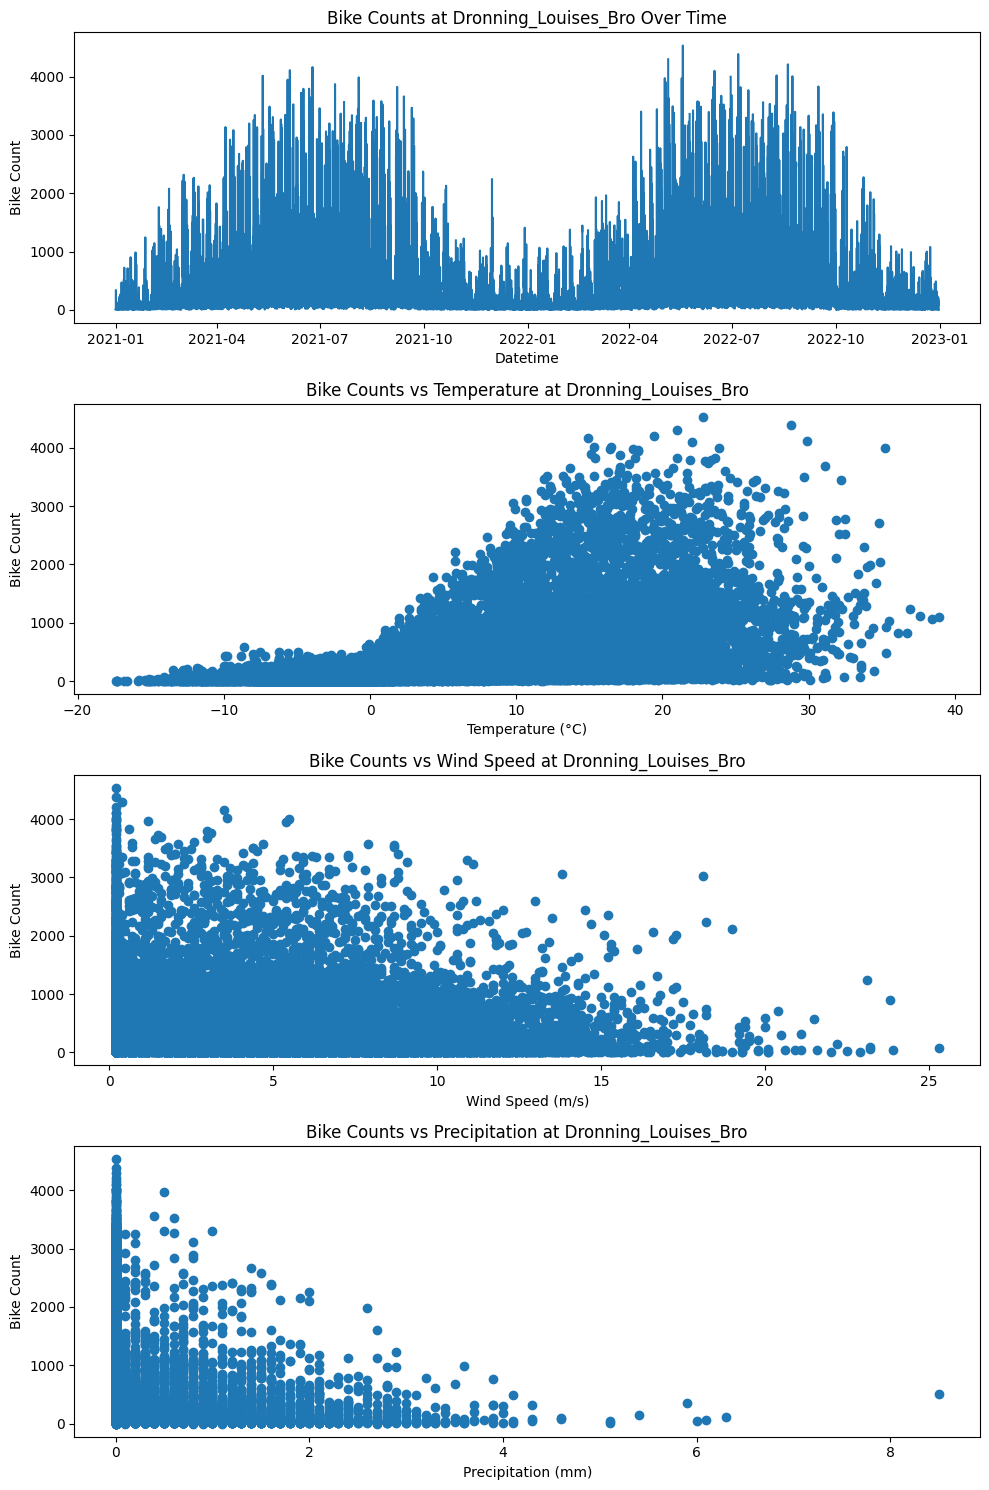

In [100]:
# plot for station station, using subplots: datetime against bike counts, temperature_C against bike counts, and wind_speed_ms and precisiption against bike counts
for station in stations["station"]:
    station_train_bike_counts = train_bike_counts[
        train_bike_counts["station"] == station
    ]
    fig, axs = plt.subplots(4, 1, figsize=(10, 15))
    axs[0].plot(train_weather["datetime"], station_train_bike_counts["bike_count"])
    axs[0].set_title(f"Bike Counts at {station} Over Time")
    axs[0].set_xlabel("Datetime")
    axs[0].set_ylabel("Bike Count")

    axs[1].scatter(
        train_weather["temperature_C"], station_train_bike_counts["bike_count"]
    )
    axs[1].set_title(f"Bike Counts vs Temperature at {station}")
    axs[1].set_xlabel("Temperature (°C)")
    axs[1].set_ylabel("Bike Count")

    axs[2].scatter(
        train_weather["wind_speed_ms"], station_train_bike_counts["bike_count"]
    )
    axs[2].set_title(f"Bike Counts vs Wind Speed at {station}")
    axs[2].set_xlabel("Wind Speed (m/s)")
    axs[2].set_ylabel("Bike Count")

    axs[3].scatter(
        train_weather["precipitation_mm"], station_train_bike_counts["bike_count"]
    )
    axs[3].set_title(f"Bike Counts vs Precipitation at {station}")
    axs[3].set_xlabel("Precipitation (mm)")
    axs[3].set_ylabel("Bike Count")
    plt.tight_layout()
    plt.show()

    break  # only plot for the first station for now

Correlation Matrix:
                  temperature_C  wind_speed_ms  precipitation_mm
temperature_C          1.000000      -0.182692         -0.072911
wind_speed_ms         -0.182692       1.000000          0.036088
precipitation_mm      -0.072911       0.036088          1.000000


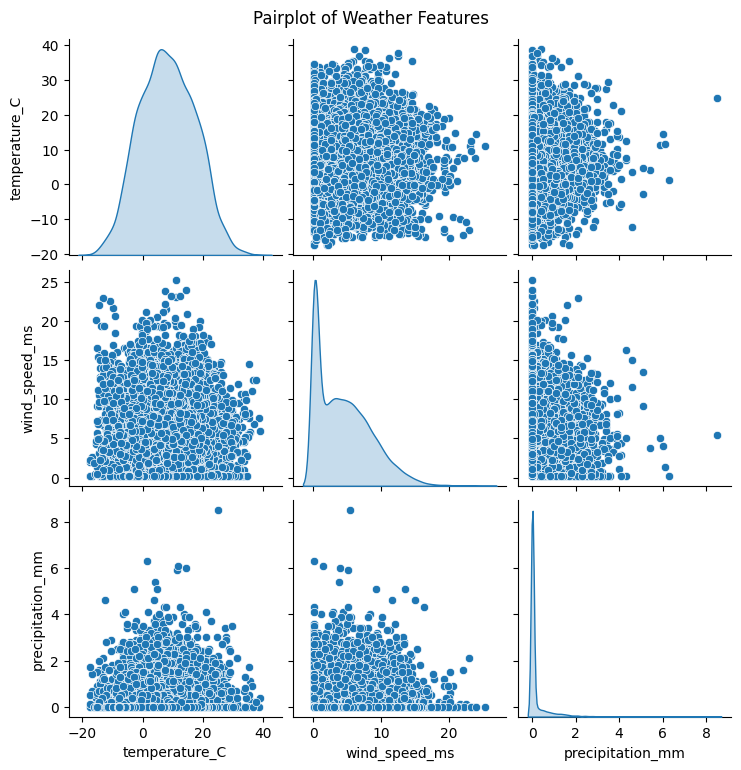

In [101]:
# evaluate the correlation between features themselves
correlation_matrix = train_weather[
    ["temperature_C", "wind_speed_ms", "precipitation_mm"]
].corr()
print("Correlation Matrix:")
print(correlation_matrix)


# actually: plot all features against each other to see if there are any interesting relationships
import seaborn as sns

sns.pairplot(
    train_weather[["temperature_C", "wind_speed_ms", "precipitation_mm"]],
    diag_kind="kde",
)
plt.suptitle("Pairplot of Weather Features", y=1.02)
plt.show()

**Investigate the hourly, weekly, and seasonal patterns. Are they consistent across stations?**

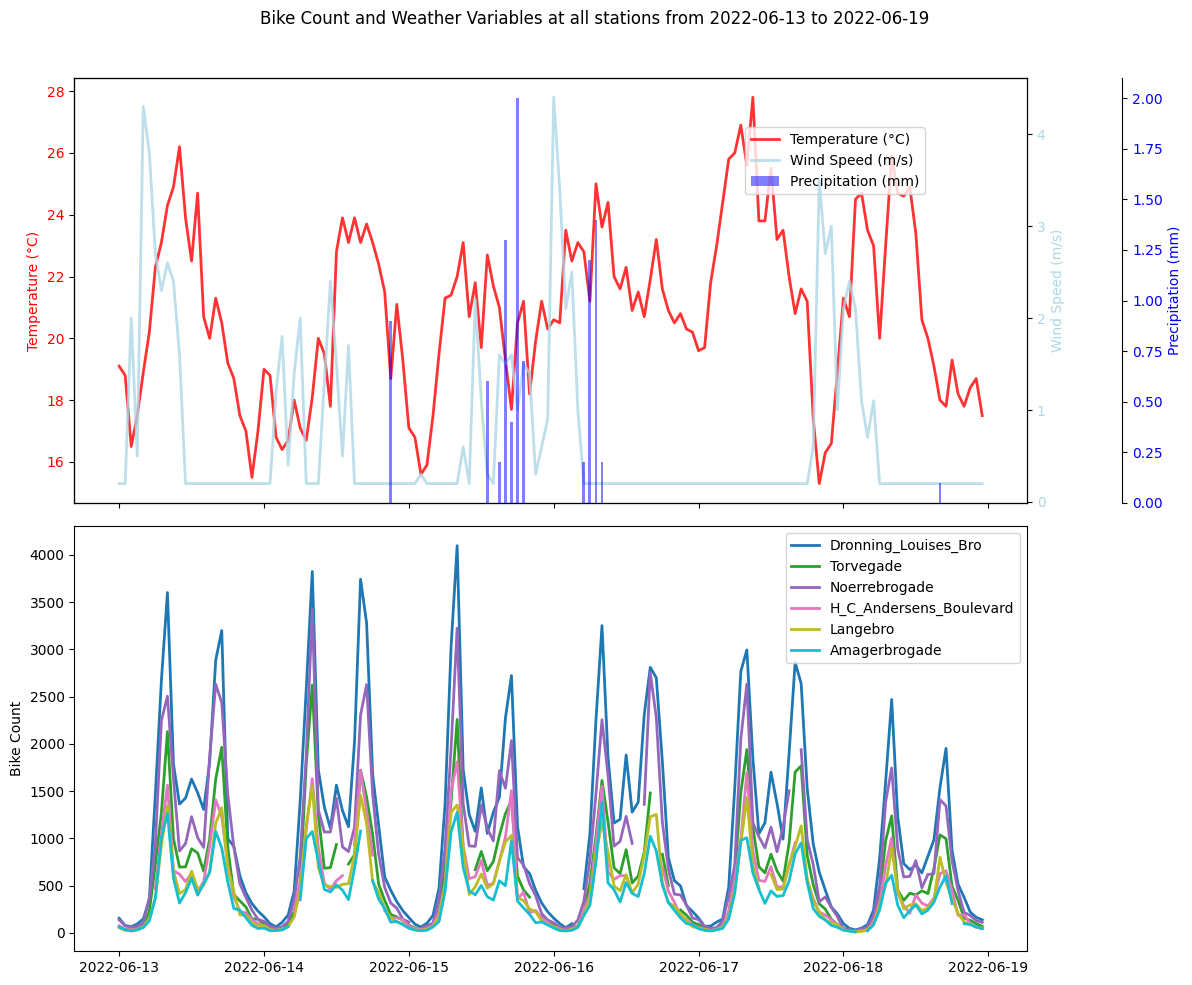

In [102]:
# pick one week from the train data for a station, torvega
# station = "Torvegade"
# station_train_bike_counts = train_bike_counts[train_bike_counts["station"] == station]
# one_week_bike_counts = station_train_bike_counts[
#     (station_train_bike_counts["datetime"] >= "2021-07-07")
#     & (station_train_bike_counts["datetime"] < "2021-07-20")
# ]
# print(one_week_bike_counts)]

day_start = pd.to_datetime("2022-06-13")
day_end = pd.to_datetime("2022-06-19")

one_week_weather = train_weather[
    (train_weather["datetime"] >= day_start) & (train_weather["datetime"] < day_end)
]
# print(one_week_weather)

# for that week, on the same figure, create two subplots:
# 1. Weather variables (temperature, wind speed, precipitation)
# 2. Bike counts for all stations (common y axis)

fig, (ax_main, ax_bike) = plt.subplots(
    2, 1, figsize=(12, 10), sharex=True, gridspec_kw={"height_ratios": [1, 1]}
)

# --- Weather subplot (top) ---
# Temperature (left axis)
ax1 = ax_main
ax1.plot(
    one_week_weather["datetime"],
    one_week_weather["temperature_C"],
    color="red",
    label="Temperature (°C)",
    zorder=2,
    linewidth=2,
    alpha=0.8,
)
ax1.set_ylabel("Temperature (°C)", color="red")
ax1.tick_params(axis="y", labelcolor="red")

# Wind speed (right axis, default position)
ax2 = ax1.twinx()
ax2.plot(
    one_week_weather["datetime"],
    one_week_weather["wind_speed_ms"],
    color="lightblue",
    label="Wind Speed (m/s)",
    zorder=2,
    linewidth=2,
    alpha=0.8,
)
# ax2.set_ylim(0, one_week_weather["wind_speed_ms"].max() * 1.5)
ax2.set_ylabel("Wind Speed (m/s)", color="lightblue")
ax2.tick_params(axis="y", labelcolor="lightblue")

# Precipitation (right axis, offset further right)
ax3 = ax1.twinx()
ax3.bar(
    one_week_weather["datetime"],
    one_week_weather["precipitation_mm"],
    color="blue",
    label="Precipitation (mm)",
    width=0.02,
    zorder=1,
    alpha=0.5,
)
ax3.set_ylabel("Precipitation (mm)", color="blue")
ax3.tick_params(axis="y", labelcolor="blue")
ax3.spines["right"].set_position(("axes", 1.1))
ax3.spines["right"].set_visible(True)

# Add legend for weather subplot
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
lines3, labels3 = ax3.get_legend_handles_labels()
ax_main.legend(
    lines1 + lines2 + lines3,
    labels1 + labels2 + labels3,
    loc="upper right",
    bbox_to_anchor=(0.9, 0.9),
)

# --- Bike counts subplot (bottom): plot all stations ---

station_names = stations["station"].unique()
colors = plt.get_cmap("tab10", len(station_names))

for idx, station_name in enumerate(station_names):
    station_counts = train_bike_counts[train_bike_counts["station"] == station_name]
    one_week_counts = station_counts[
        (station_counts["datetime"] >= day_start)
        & (station_counts["datetime"] < day_end)
    ]
    ax_bike.plot(
        one_week_counts["datetime"],
        one_week_counts["bike_count"],
        label=station_name,
        color=colors(idx),
        linewidth=2,
    )

ax_bike.set_ylabel("Bike Count", color="black")
ax_bike.tick_params(axis="y", labelcolor="black")
ax_bike.legend(loc="upper right")

plt.suptitle(
    f"Bike Count and Weather Variables at all stations from {day_start.date()} to {day_end.date()}"
)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

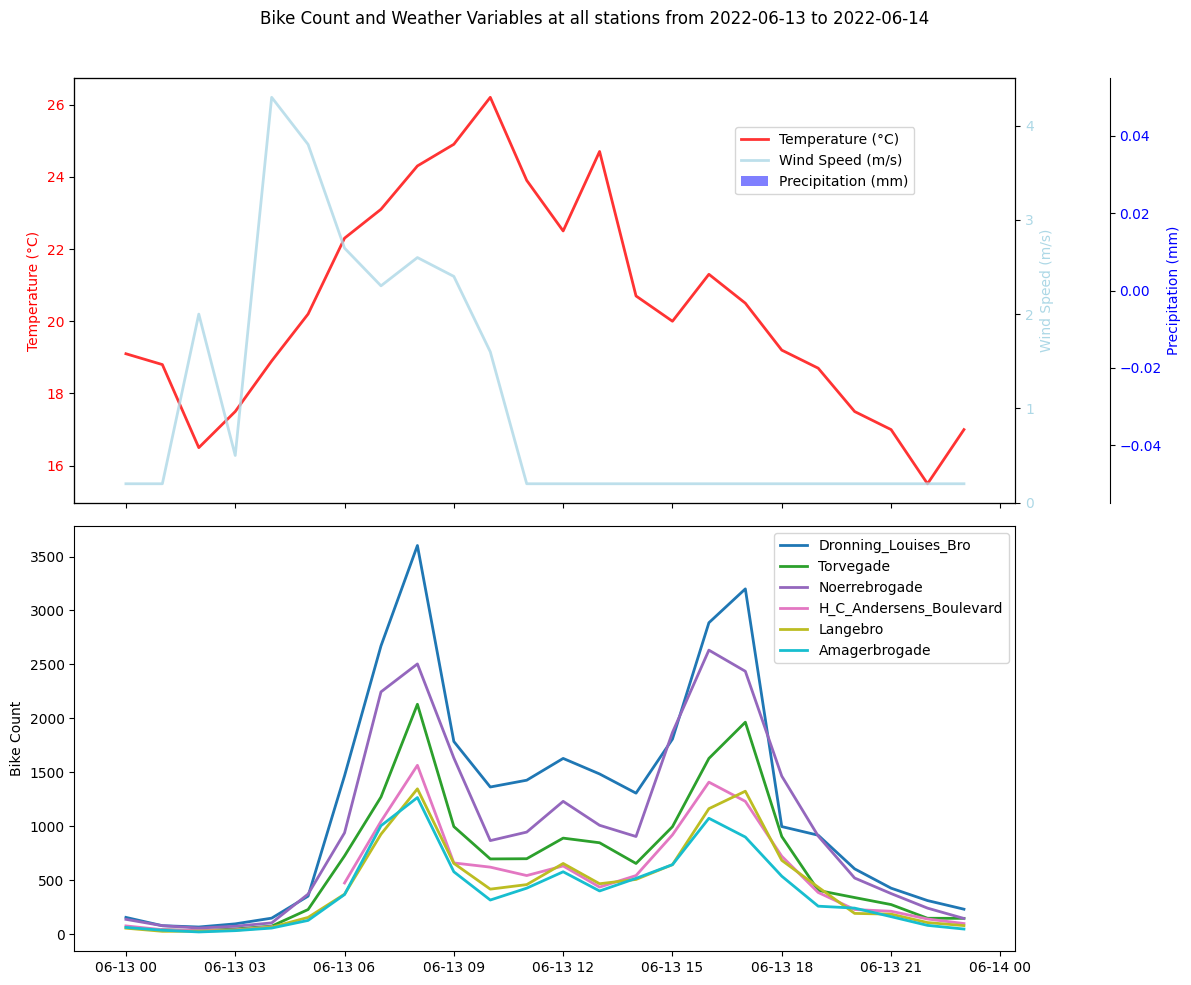

In [103]:
# pick one week from the train data for a station, torvega
# station = "Torvegade"
# station_train_bike_counts = train_bike_counts[train_bike_counts["station"] == station]
# one_week_bike_counts = station_train_bike_counts[
#     (station_train_bike_counts["datetime"] >= "2021-07-07")
#     & (station_train_bike_counts["datetime"] < "2021-07-20")
# ]
# print(one_week_bike_counts)]

day_start = pd.to_datetime("2022-06-13")
day_end = pd.to_datetime("2022-06-14")

one_week_weather = train_weather[
    (train_weather["datetime"] >= day_start) & (train_weather["datetime"] < day_end)
]
# print(one_week_weather)

# for that week, on the same figure, create two subplots:
# 1. Weather variables (temperature, wind speed, precipitation)
# 2. Bike counts for all stations (common y axis)

fig, (ax_main, ax_bike) = plt.subplots(
    2, 1, figsize=(12, 10), sharex=True, gridspec_kw={"height_ratios": [1, 1]}
)

# --- Weather subplot (top) ---
# Temperature (left axis)
ax1 = ax_main
ax1.plot(
    one_week_weather["datetime"],
    one_week_weather["temperature_C"],
    color="red",
    label="Temperature (°C)",
    zorder=2,
    linewidth=2,
    alpha=0.8,
)
ax1.set_ylabel("Temperature (°C)", color="red")
ax1.tick_params(axis="y", labelcolor="red")

# Wind speed (right axis, default position)
ax2 = ax1.twinx()
ax2.plot(
    one_week_weather["datetime"],
    one_week_weather["wind_speed_ms"],
    color="lightblue",
    label="Wind Speed (m/s)",
    zorder=2,
    linewidth=2,
    alpha=0.8,
)
# ax2.set_ylim(0, one_week_weather["wind_speed_ms"].max() * 1.5)
ax2.set_ylabel("Wind Speed (m/s)", color="lightblue")
ax2.tick_params(axis="y", labelcolor="lightblue")

# Precipitation (right axis, offset further right)
ax3 = ax1.twinx()
ax3.bar(
    one_week_weather["datetime"],
    one_week_weather["precipitation_mm"],
    color="blue",
    label="Precipitation (mm)",
    width=0.02,
    zorder=1,
    alpha=0.5,
)
ax3.set_ylabel("Precipitation (mm)", color="blue")
ax3.tick_params(axis="y", labelcolor="blue")
ax3.spines["right"].set_position(("axes", 1.1))
ax3.spines["right"].set_visible(True)

# Add legend for weather subplot
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
lines3, labels3 = ax3.get_legend_handles_labels()
ax_main.legend(
    lines1 + lines2 + lines3,
    labels1 + labels2 + labels3,
    loc="upper right",
    bbox_to_anchor=(0.9, 0.9),
)

# --- Bike counts subplot (bottom): plot all stations ---

station_names = stations["station"].unique()
colors = plt.get_cmap("tab10", len(station_names))

for idx, station_name in enumerate(station_names):
    station_counts = train_bike_counts[train_bike_counts["station"] == station_name]
    one_week_counts = station_counts[
        (station_counts["datetime"] >= day_start)
        & (station_counts["datetime"] < day_end)
    ]
    ax_bike.plot(
        one_week_counts["datetime"],
        one_week_counts["bike_count"],
        label=station_name,
        color=colors(idx),
        linewidth=2,
    )

ax_bike.set_ylabel("Bike Count", color="black")
ax_bike.tick_params(axis="y", labelcolor="black")
ax_bike.legend(loc="upper right")

plt.suptitle(
    f"Bike Count and Weather Variables at all stations from {day_start.date()} to {day_end.date()}"
)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

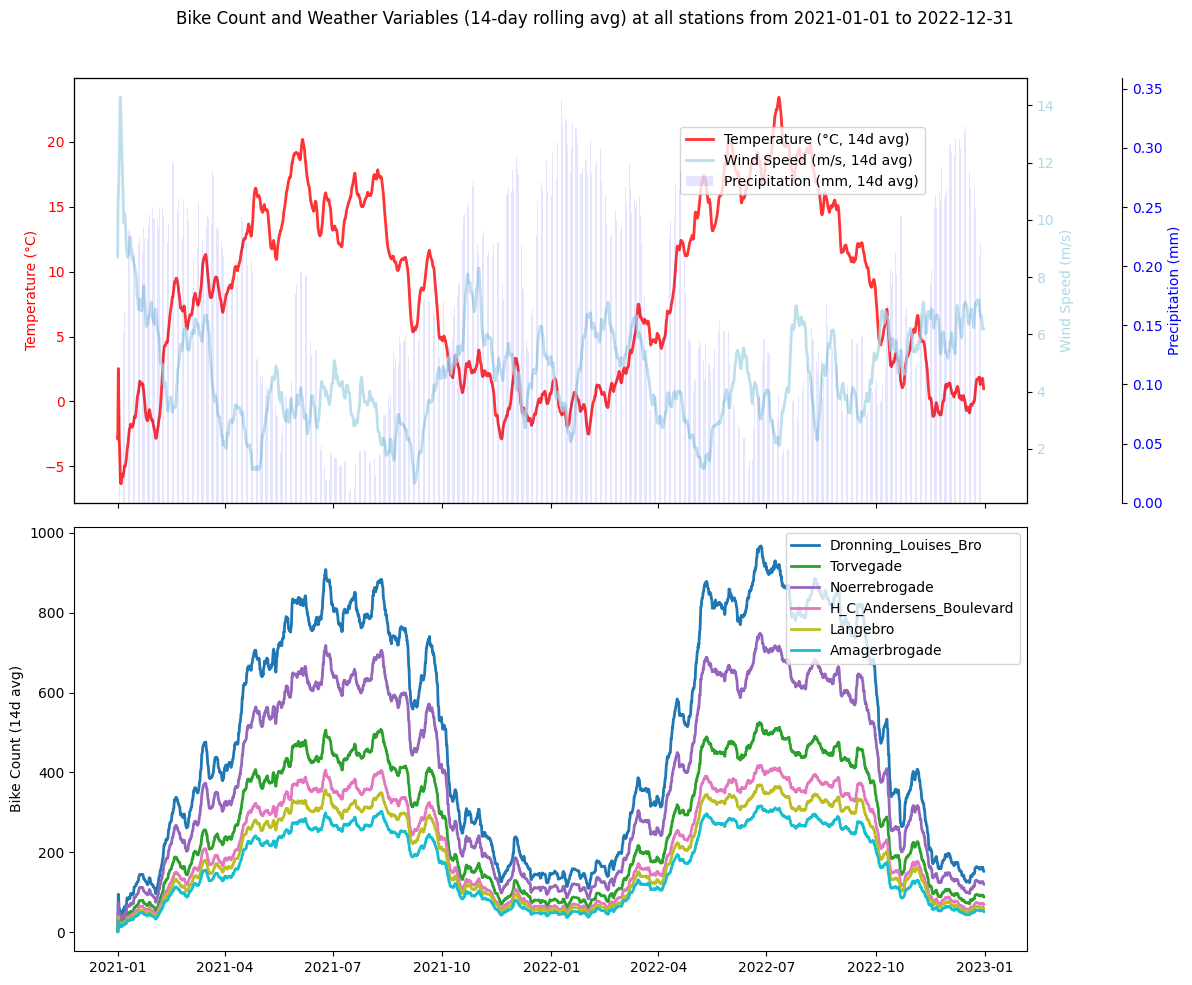

In [104]:
# pick one week from the train data for a station, torvega
# station = "Torvegade"
# station_train_bike_counts = train_bike_counts[train_bike_counts["station"] == station]
# one_week_bike_counts = station_train_bike_counts[
#     (station_train_bike_counts["datetime"] >= "2021-07-07")
#     & (station_train_bike_counts["datetime"] < "2021-07-20")
# ]
# print(one_week_bike_counts)]

day_start = pd.to_datetime("2021-01-01")
day_end = pd.to_datetime("2022-12-31")

one_week_weather = train_weather[
    (train_weather["datetime"] >= day_start) & (train_weather["datetime"] < day_end)
]
# print(one_week_weather)

# for that period, on the same figure, create two subplots:
# 1. Weather variables (temperature, wind speed, precipitation)
# 2. Bike counts for all stations (common y axis), using 14-day rolling averages

fig, (ax_main, ax_bike) = plt.subplots(
    2, 1, figsize=(12, 10), sharex=True, gridspec_kw={"height_ratios": [1, 1]}
)

# --- Weather subplot (top) ---
# Temperature (left axis)
ax1 = ax_main
ax1.plot(
    one_week_weather["datetime"],
    one_week_weather["temperature_C"].rolling(window=14 * 24, min_periods=1).mean(),
    color="red",
    label="Temperature (°C, 14d avg)",
    zorder=2,
    linewidth=2,
    alpha=0.8,
)
ax1.set_ylabel("Temperature (°C)", color="red")
ax1.tick_params(axis="y", labelcolor="red")

# Wind speed (right axis, default position)
ax2 = ax1.twinx()
ax2.plot(
    one_week_weather["datetime"],
    one_week_weather["wind_speed_ms"].rolling(window=14 * 24, min_periods=1).mean(),
    color="lightblue",
    label="Wind Speed (m/s, 14d avg)",
    zorder=2,
    linewidth=2,
    alpha=0.8,
)
ax2.set_ylabel("Wind Speed (m/s)", color="lightblue")
ax2.tick_params(axis="y", labelcolor="lightblue")

# Precipitation (right axis, offset further right)
ax3 = ax1.twinx()
ax3.bar(
    one_week_weather["datetime"],
    one_week_weather["precipitation_mm"].rolling(window=14 * 24, min_periods=1).mean(),
    color="blue",
    label="Precipitation (mm, 14d avg)",
    width=0.02,
    zorder=1,
    alpha=0.1,
)
ax3.set_ylabel("Precipitation (mm)", color="blue")
ax3.tick_params(axis="y", labelcolor="blue")
ax3.spines["right"].set_position(("axes", 1.1))
ax3.spines["right"].set_visible(True)

# Add legend for weather subplot
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
lines3, labels3 = ax3.get_legend_handles_labels()
ax_main.legend(
    lines1 + lines2 + lines3,
    labels1 + labels2 + labels3,
    loc="upper right",
    bbox_to_anchor=(0.9, 0.9),
)

# --- Bike counts subplot (bottom): plot all stations, 14-day rolling average ---

station_names = stations["station"].unique()
colors = plt.get_cmap("tab10", len(station_names))

for idx, station_name in enumerate(station_names):
    station_counts = train_bike_counts[train_bike_counts["station"] == station_name]
    one_week_counts = station_counts[
        (station_counts["datetime"] >= day_start)
        & (station_counts["datetime"] < day_end)
    ]
    # 14-day rolling average (assuming hourly data: 14*24=336)
    bike_count_rolling = (
        one_week_counts["bike_count"].rolling(window=14 * 24, min_periods=1).mean()
    )
    ax_bike.plot(
        one_week_counts["datetime"],
        bike_count_rolling,
        label=station_name,
        color=colors(idx),
        linewidth=2,
    )

ax_bike.set_ylabel("Bike Count (14d avg)", color="black")
ax_bike.tick_params(axis="y", labelcolor="black")
ax_bike.legend(loc="upper right")

plt.suptitle(
    f"Bike Count and Weather Variables (14-day rolling avg) at all stations from {day_start.date()} to {day_end.date()}"
)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

**Investigate the relationship between weather variables and bicycle counts. Which variables appear most influential?**

In [105]:
# I have done it already above.

**How should missing values be handled? Document your choice.**

In [106]:
# In my opinion missing data should be removed, if it accounts for 2% or less of the data, and we have 3 years available of the data. Seriously. Does not make any sense to try to fix it.
# other option could be to take means in between, but seriously, not sure why would you do it.
# I would say: unless I use lag features, I would simply remove it. We can come back here later.
# For now - I will simply remove it.

# Part 2 — Baseline Model

**Choose one station to focus on initially (e.g. Dronning Louises Bro).**

In [107]:
# Tovergade station to focus on.

**Build a simple linear regression model using raw features: temperature, wind speed, precipitation, hour, day of week, and month.**

In [108]:
from sklearn.linear_model import LinearRegression

# for now, drop the missing values
lr = LinearRegression()
train_bike_counts_torvegade = train_bike_counts[
    train_bike_counts["station"] == "Torvegade"
]

train_data = pd.merge(
    train_bike_counts_torvegade,
    train_weather,
    on="datetime",
    how="inner",
)

train_data = train_data.dropna(
    subset=["bike_count"]
)  # drop rows where bike_count is missing

train_data["hour"] = train_data["datetime"].dt.hour
train_data["dayofweek"] = train_data["datetime"].dt.dayofweek
train_data["month"] = train_data["datetime"].dt.month
features = [
    "temperature_C",
    "wind_speed_ms",
    "precipitation_mm",
    "hour",
    "dayofweek",
    "month",
]
X_train = train_data[features]
y_train = train_data["bike_count"]

**Evaluate the model on the validation set using appropriate metrics (e.g. RMSE, R², MAE). Visualize predictions vs. actual counts.**

In [109]:
# ok, so basically, do the timeseriessplit, s.t. we evaluate on each week of the train data
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np

# Calculate number of weeks in the training data
n_weeks = int((train_data["datetime"].max() - train_data["datetime"].min()).days // 7)
n_splits = max(2, n_weeks - 1)  # at least 2 splits

tscv = TimeSeriesSplit(n_splits=n_splits)

rmse_list = []
# r2_list = []
mae_list = []
preds_log = []

for fold, (train_index, val_index) in enumerate(tscv.split(X_train)):
    X_tr, X_val = X_train.iloc[train_index], X_train.iloc[val_index]
    y_tr, y_val = y_train.iloc[train_index], y_train.iloc[val_index]
    lr.fit(X_tr, y_tr)
    y_pred = lr.predict(X_val)
    rmse = np.sqrt(mean_squared_error(y_val, y_pred))
    preds_log.append((y_val, y_pred, train_data.iloc[val_index]["datetime"]))
    # r2 = r2_score(y_val, y_pred)
    mae = mean_absolute_error(y_val, y_pred)
    rmse_list.append(rmse)
    # r2_list.append(r2)
    mae_list.append(mae)
    # print(f"Fold {fold + 1}: RMSE={rmse:.2f}, R2={r2:.3f}, MAE={mae:.2f}")
    print(f"Fold {fold + 1}: RMSE={rmse:.2f}")

print(f"\nAverage RMSE: {np.mean(rmse_list):.2f}")
# print(f"Average R2: {np.mean(r2_list):.3f}")
print(f"Average MAE: {np.mean(mae_list):.2f}")

Fold 1: RMSE=82.19
Fold 2: RMSE=67.33
Fold 3: RMSE=65.03
Fold 4: RMSE=149.01
Fold 5: RMSE=170.79
Fold 6: RMSE=158.94
Fold 7: RMSE=142.49
Fold 8: RMSE=261.57
Fold 9: RMSE=225.98
Fold 10: RMSE=181.42
Fold 11: RMSE=249.52
Fold 12: RMSE=196.11
Fold 13: RMSE=303.09
Fold 14: RMSE=365.13
Fold 15: RMSE=385.08
Fold 16: RMSE=311.57
Fold 17: RMSE=397.08
Fold 18: RMSE=383.59
Fold 19: RMSE=430.87
Fold 20: RMSE=424.12
Fold 21: RMSE=452.91
Fold 22: RMSE=346.60
Fold 23: RMSE=455.00
Fold 24: RMSE=426.57
Fold 25: RMSE=379.48
Fold 26: RMSE=424.13
Fold 27: RMSE=412.29
Fold 28: RMSE=378.83
Fold 29: RMSE=443.62
Fold 30: RMSE=463.81
Fold 31: RMSE=358.68
Fold 32: RMSE=384.16
Fold 33: RMSE=363.51
Fold 34: RMSE=263.25
Fold 35: RMSE=411.80
Fold 36: RMSE=315.67
Fold 37: RMSE=356.58
Fold 38: RMSE=216.78
Fold 39: RMSE=179.24
Fold 40: RMSE=141.51
Fold 41: RMSE=215.87
Fold 42: RMSE=133.90
Fold 43: RMSE=162.42
Fold 44: RMSE=114.49
Fold 45: RMSE=131.20
Fold 46: RMSE=123.03
Fold 47: RMSE=177.77
Fold 48: RMSE=122.78
Fold

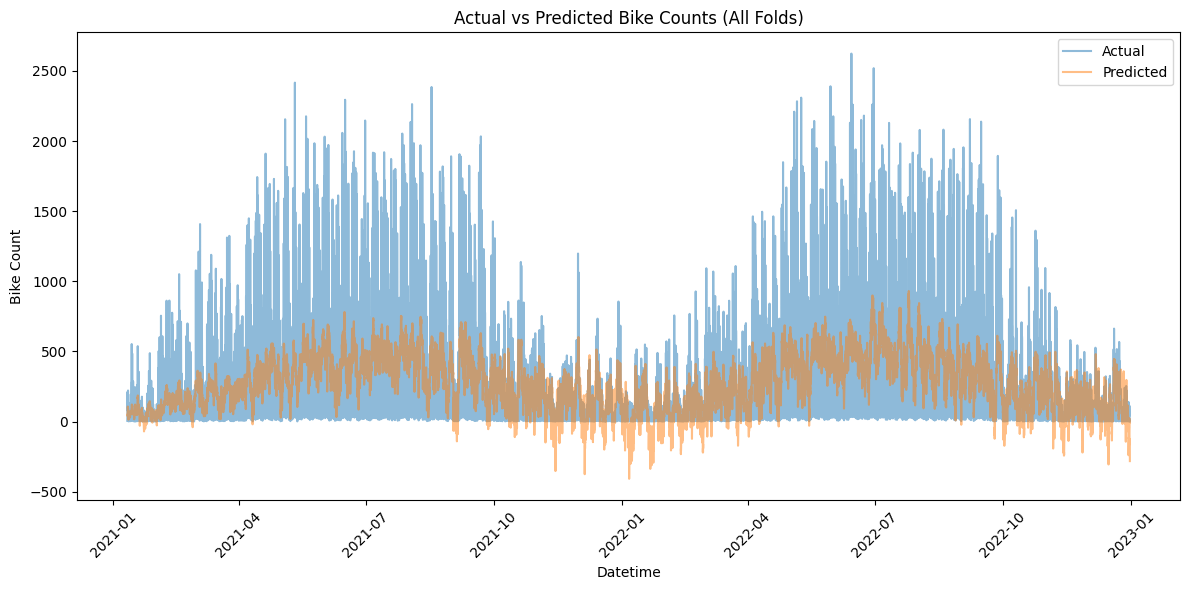

In [110]:
# ok, simply plot for everything in the train / val data, to see how it looks like

actuals, preds, dates = zip(*preds_log)
preds = np.concatenate(preds).tolist()
actuals = np.concatenate(actuals).tolist()
dates = np.concatenate(dates).tolist()

plt.figure(figsize=(12, 6))
plt.plot(dates, actuals, label="Actual", alpha=0.5)
plt.plot(dates, preds, label="Predicted", alpha=0.5)
plt.title("Actual vs Predicted Bike Counts (All Folds)")
plt.xlabel("Datetime")
plt.ylabel("Bike Count")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

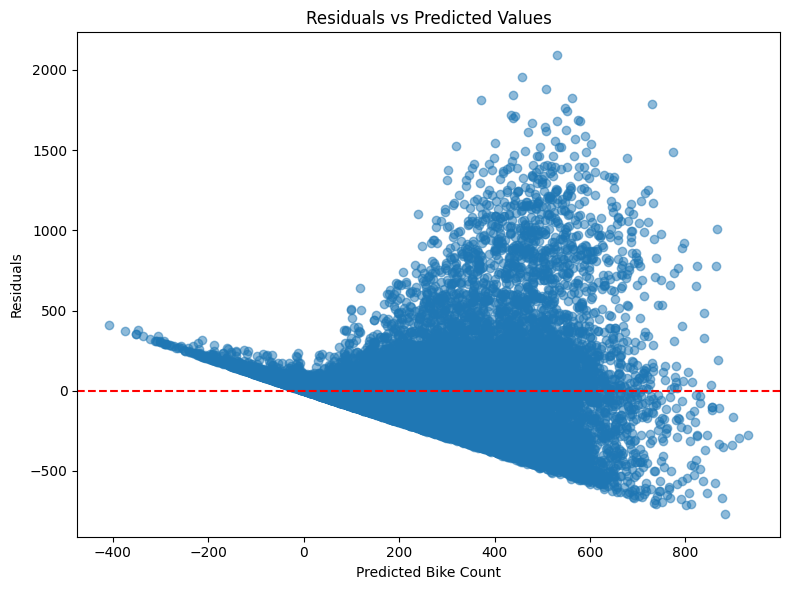

In [111]:
# plot residuals vs predicted values
residuals = np.array(actuals) - np.array(preds)
plt.figure(figsize=(8, 6))
plt.scatter(preds, residuals, alpha=0.5)
plt.axhline(0, color="red", linestyle="--")
plt.title("Residuals vs Predicted Values")
plt.xlabel("Predicted Bike Count")
plt.ylabel("Residuals")
plt.tight_layout()
plt.show()


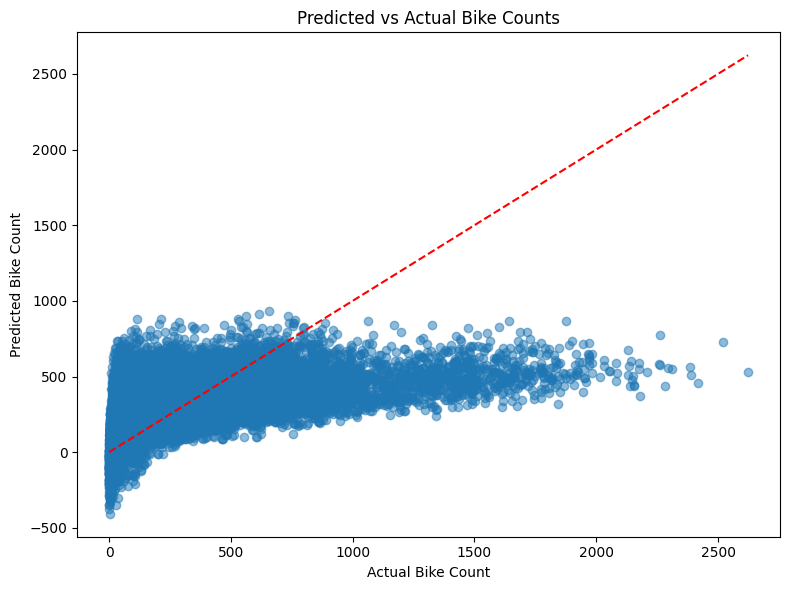

In [112]:
# plot predicted vs actuals
plt.figure(figsize=(8, 6))
plt.scatter(actuals, preds, alpha=0.5)
plt.plot(
    [min(actuals), max(actuals)],
    [min(actuals), max(actuals)],
    color="red",
    linestyle="--",
)
plt.title("Predicted vs Actual Bike Counts")
plt.xlabel("Actual Bike Count")
plt.ylabel("Predicted Bike Count")
plt.tight_layout()
plt.show()

## Log Transforms

In [113]:
# do the quick retrain, applying log transformation to the target variable, to see if it improves the performance
from seaborn.external.husl import m
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np

lr_log = LinearRegression()
train_bike_counts_torvegade = train_bike_counts[
    train_bike_counts["station"] == "Torvegade"
]
train_data = pd.merge(
    train_bike_counts_torvegade,
    train_weather,
    on="datetime",
    how="inner",
)
train_data = train_data.dropna(subset=["bike_count"])
train_data["hour"] = train_data["datetime"].dt.hour
train_data["dayofweek"] = train_data["datetime"].dt.dayofweek
train_data["month"] = train_data["datetime"].dt.month
features = [
    "temperature_C",
    "wind_speed_ms",
    "precipitation_mm",
    "hour",
    "dayofweek",
    "month",
]
X_train = train_data[features]
y_train_log = np.log1p(
    train_data["bike_count"]
)  # log(1 + bike_count) to handle zero counts
tscv = TimeSeriesSplit(n_splits=n_splits)
rmse_log_list = []
mae_log_list = []
preds_log = []
for fold, (train_index, val_index) in enumerate(tscv.split(X_train)):
    X_tr, X_val = X_train.iloc[train_index], X_train.iloc[val_index]
    y_tr_log, y_val_log = y_train_log.iloc[train_index], y_train_log.iloc[val_index]
    lr_log.fit(X_tr, y_tr_log)
    y_pred_log = lr_log.predict(X_val)
    y_pred = np.expm1(y_pred_log)  # inverse of log1p
    rmse_log = np.sqrt(mean_squared_error(np.expm1(y_val_log), y_pred))
    mae_log = mean_absolute_error(np.expm1(y_val_log), y_pred)
    rmse_log_list.append(rmse_log)
    mae_log_list.append(mae_log)
    preds_log.append(
        (np.expm1(y_val_log), y_pred, train_data.iloc[val_index]["datetime"])
    )
    print(f"Fold {fold + 1}: RMSE (log model)={rmse_log:.2f}")
print(f"\nAverage RMSE (log model): {np.mean(rmse_log_list):.2f}")
print(f"Average MAE (log model): {np.mean(mae_log_list):.2f}")

Fold 1: RMSE (log model)=85.76
Fold 2: RMSE (log model)=62.75
Fold 3: RMSE (log model)=73.20
Fold 4: RMSE (log model)=174.02
Fold 5: RMSE (log model)=169.39
Fold 6: RMSE (log model)=164.25
Fold 7: RMSE (log model)=158.71
Fold 8: RMSE (log model)=273.49
Fold 9: RMSE (log model)=253.28
Fold 10: RMSE (log model)=212.47
Fold 11: RMSE (log model)=282.78
Fold 12: RMSE (log model)=225.22
Fold 13: RMSE (log model)=336.70
Fold 14: RMSE (log model)=379.27
Fold 15: RMSE (log model)=538.49
Fold 16: RMSE (log model)=329.30
Fold 17: RMSE (log model)=416.36
Fold 18: RMSE (log model)=412.70
Fold 19: RMSE (log model)=492.40
Fold 20: RMSE (log model)=502.24
Fold 21: RMSE (log model)=531.25
Fold 22: RMSE (log model)=433.54
Fold 23: RMSE (log model)=560.17
Fold 24: RMSE (log model)=456.05
Fold 25: RMSE (log model)=436.22
Fold 26: RMSE (log model)=443.39
Fold 27: RMSE (log model)=442.35
Fold 28: RMSE (log model)=434.03
Fold 29: RMSE (log model)=487.93
Fold 30: RMSE (log model)=517.59
Fold 31: RMSE (log mod

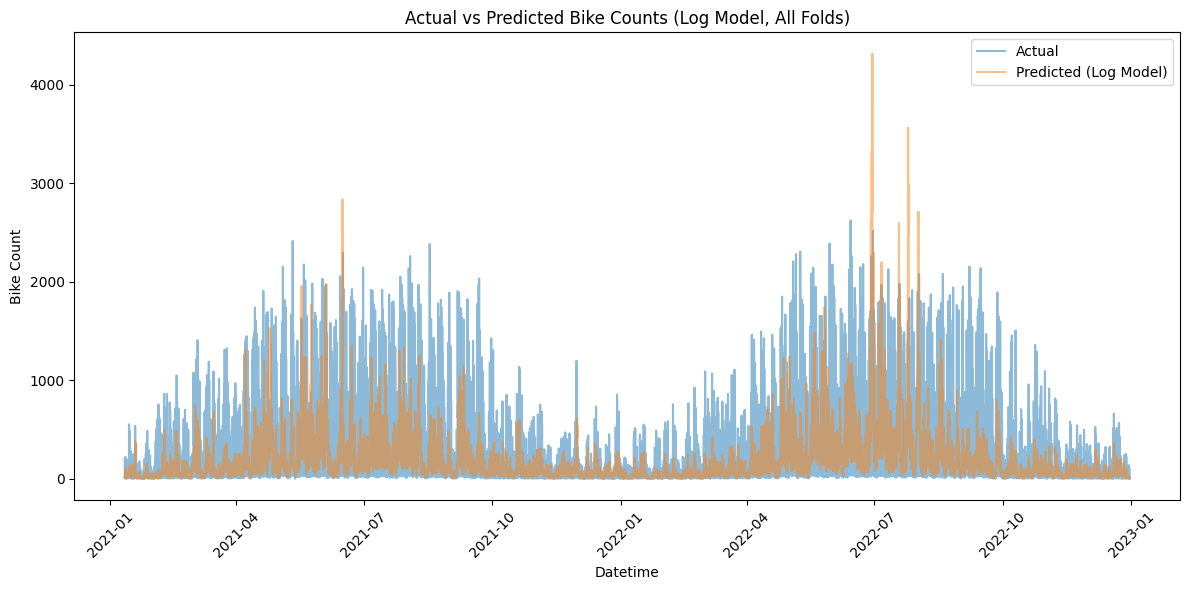

In [114]:
# visualise the predictions of the log model
actuals_log, preds_log_values, dates_log = zip(*preds_log)
preds_log_values = np.concatenate(preds_log_values).tolist()
actuals_log = np.concatenate(actuals_log).tolist()
dates_log = np.concatenate(dates_log).tolist()
plt.figure(figsize=(12, 6))
plt.plot(dates_log, actuals_log, label="Actual", alpha=0.5)
plt.plot(dates_log, preds_log_values, label="Predicted (Log Model)", alpha=0.5)
plt.title("Actual vs Predicted Bike Counts (Log Model, All Folds)")
plt.xlabel("Datetime")
plt.ylabel("Bike Count")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

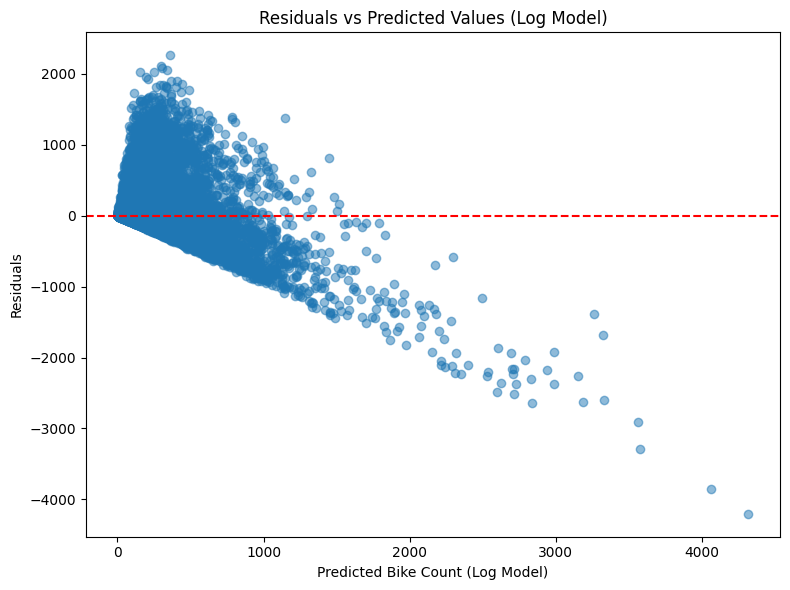

In [115]:
# plot the residuals of the log model
residuals_log = np.array(actuals_log) - np.array(preds_log_values)
plt.figure(figsize=(8, 6))
plt.scatter(preds_log_values, residuals_log, alpha=0.5)
plt.axhline(0, color="red", linestyle="--")
plt.title("Residuals vs Predicted Values (Log Model)")
plt.xlabel("Predicted Bike Count (Log Model)")
plt.ylabel("Residuals")
plt.tight_layout()
plt.show()

## Further examination

**Examine the predicted errors. Are there systematic patterns that suggest the model is missing something?**

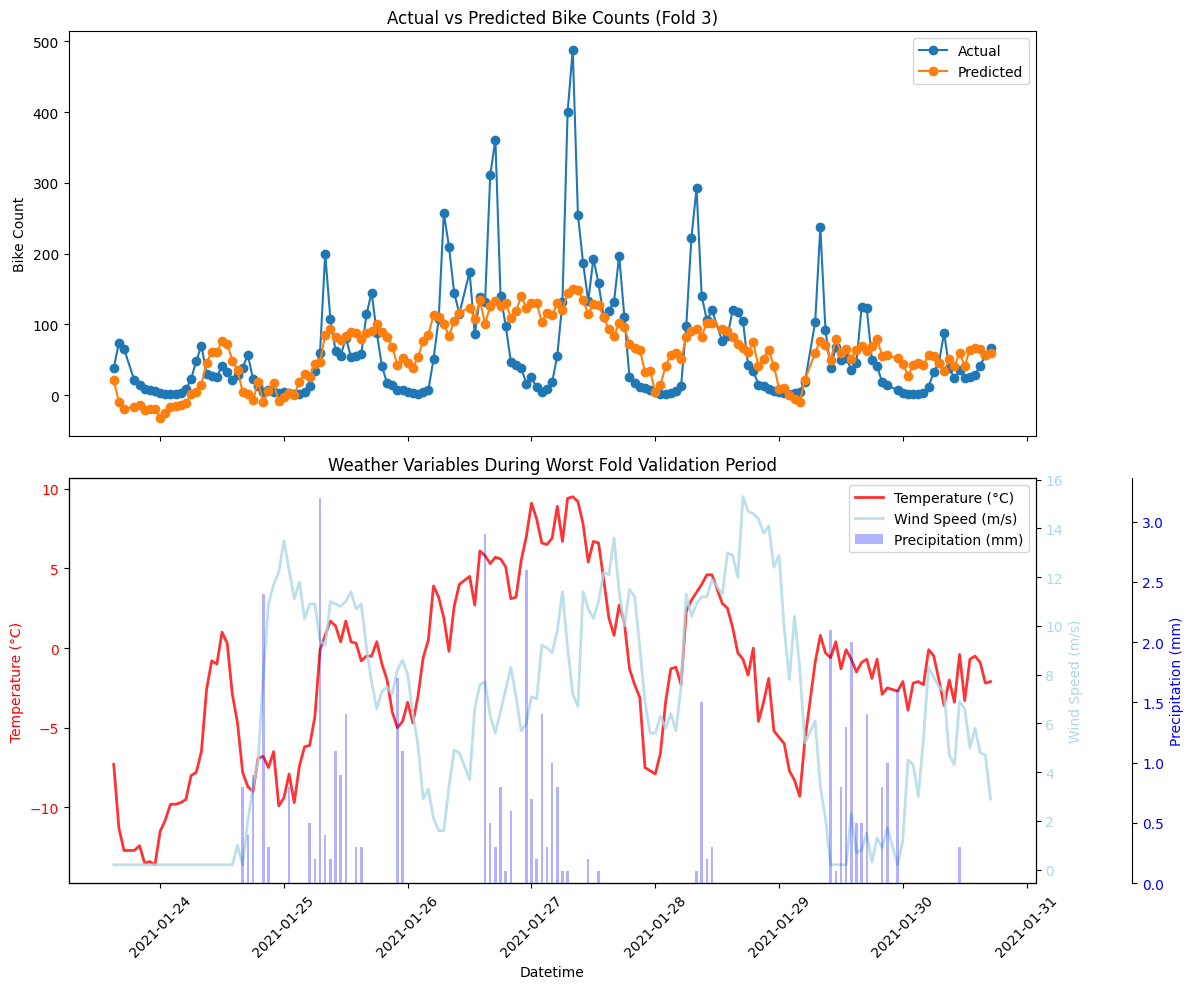

In [164]:
# let's examine the predictions vs actuals for the worst fold
worst_fold = np.argsort(rmse_list)[0]
train_index, val_index = list(tscv.split(X_train))[worst_fold]
X_tr, X_val = X_train.iloc[train_index], X_train.iloc[val_index]
y_tr, y_val = y_train.iloc[train_index], y_train.iloc[val_index]
lr.fit(X_tr, y_tr)
y_pred = lr.predict(X_val)

# Get datetimes for the validation period
val_datetimes = train_data["datetime"].iloc[val_index]

fig, axs = plt.subplots(
    2, 1, figsize=(12, 10), sharex=True, gridspec_kw={"height_ratios": [1, 1]}
)

# Top: Actual vs Predicted Bike Counts
axs[0].plot(val_datetimes, y_val, label="Actual", marker="o")
axs[0].plot(val_datetimes, y_pred, label="Predicted", marker="o")
axs[0].set_title(f"Actual vs Predicted Bike Counts (Fold {worst_fold + 1})")
axs[0].set_xlabel("")
axs[0].set_ylabel("Bike Count")
axs[0].legend()
axs[0].tick_params(axis="x", rotation=45)

# Bottom: Weather variables for the same period
weather_val = train_weather[train_weather["datetime"].isin(val_datetimes)]
ax1 = axs[1]
ax1.plot(
    weather_val["datetime"],
    weather_val["temperature_C"],
    color="red",
    label="Temperature (°C)",
    linewidth=2,
    alpha=0.8,
)
ax1.set_ylabel("Temperature (°C)", color="red")
ax1.tick_params(axis="y", labelcolor="red")

ax2 = ax1.twinx()
ax2.plot(
    weather_val["datetime"],
    weather_val["wind_speed_ms"],
    color="lightblue",
    label="Wind Speed (m/s)",
    linewidth=2,
    alpha=0.8,
)
ax2.set_ylabel("Wind Speed (m/s)", color="lightblue")
ax2.tick_params(axis="y", labelcolor="lightblue")

ax3 = ax1.twinx()
ax3.bar(
    weather_val["datetime"],
    weather_val["precipitation_mm"],
    color="blue",
    label="Precipitation (mm)",
    width=0.02,
    alpha=0.3,
)
ax3.set_ylabel("Precipitation (mm)", color="blue")
ax3.tick_params(axis="y", labelcolor="blue")
ax3.spines["right"].set_position(("axes", 1.1))
ax3.spines["right"].set_visible(True)

# Add legend for weather subplot
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
lines3, labels3 = ax3.get_legend_handles_labels()
ax1.legend(lines1 + lines2 + lines3, labels1 + labels2 + labels3, loc="upper right")

axs[1].set_xlabel("Datetime")
axs[1].set_title("Weather Variables During Worst Fold Validation Period")
axs[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [117]:
X_train

,temperature_C,wind_speed_ms,precipitation_mm,hour,dayofweek,month
0,-2.8,8.7,0.0,0,4,1
1,-3.0,9.7,0.0,1,4,1
2,-1.8,10.2,0.0,2,4,1
3,0.8,11.0,0.0,3,4,1
4,0.9,11.0,0.0,4,4,1
...,...,...,...,...,...,...
17491,-13.1,3.5,1.3,19,4,12
17492,-12.8,4.7,1.2,20,4,12
17493,-14.5,5.1,0.2,21,4,12
17495,-14.6,4.9,0.0,23,4,12


In [118]:
train_data

,datetime,station,latitude,longitude,bike_count,temperature_C,wind_speed_ms,precipitation_mm,hour,dayofweek,month
0,2021-01-01 00:00:00,Torvegade,55.6737,12.5862,2.0,-2.8,8.7,0.0,0,4,1
1,2021-01-01 01:00:00,Torvegade,55.6737,12.5862,1.0,-3.0,9.7,0.0,1,4,1
2,2021-01-01 02:00:00,Torvegade,55.6737,12.5862,1.0,-1.8,10.2,0.0,2,4,1
3,2021-01-01 03:00:00,Torvegade,55.6737,12.5862,2.0,0.8,11.0,0.0,3,4,1
4,2021-01-01 04:00:00,Torvegade,55.6737,12.5862,3.0,0.9,11.0,0.0,4,4,1
...,...,...,...,...,...,...,...,...,...,...,...
17491,2022-12-30 19:00:00,Torvegade,55.6737,12.5862,28.0,-13.1,3.5,1.3,19,4,12
17492,2022-12-30 20:00:00,Torvegade,55.6737,12.5862,14.0,-12.8,4.7,1.2,20,4,12
17493,2022-12-30 21:00:00,Torvegade,55.6737,12.5862,16.0,-14.5,5.1,0.2,21,4,12
17495,2022-12-30 23:00:00,Torvegade,55.6737,12.5862,8.0,-14.6,4.9,0.0,23,4,12


**Residual diagnostics — temperature.** The two panels examine residuals against temperature.

*Right panel (clean signal).* Splitting by weekday vs weekend, the binned-mean residual curves visibly diverge in slope — at the same temperature, weekend residuals trend more negative than weekday residuals as it warms. Same input, different residual structure: a textbook interaction signal that motivates a `temperature × is_weekend` term.

*Left panel (weaker signal, treated cautiously).* The overall binned mean is non-zero and monotonically decreasing across temperature, so the linear-in-temperature assumption is misspecified — some non-linear term (e.g. a quadratic) is warranted. The shape is not a clean inverted-U, however, and the variance of the residuals fans out with temperature. Part of that heteroscedasticity is spillover from the missing cyclic time features (warm temperatures coincide with summer rush hours that the raw baseline cannot represent), so we use this plot only as evidence that *some* non-linearity in temperature exists, and let the broader feature expansion plus ridge regularisation in Part 3 select the appropriate form.

**Residual diagnostics — temperature.** Two further residual plots help diagnose what the linear baseline is missing. The left panel plots residuals against temperature: a curved binned mean indicates a non-linear (likely inverted-U) temperature response that a linear `temperature_C` term cannot capture, motivating a quadratic term. The right panel splits the same plot by weekday/weekend: if the binned curves diverge across groups, the temperature effect itself depends on calendar context, motivating a `temperature × is_weekend` interaction.

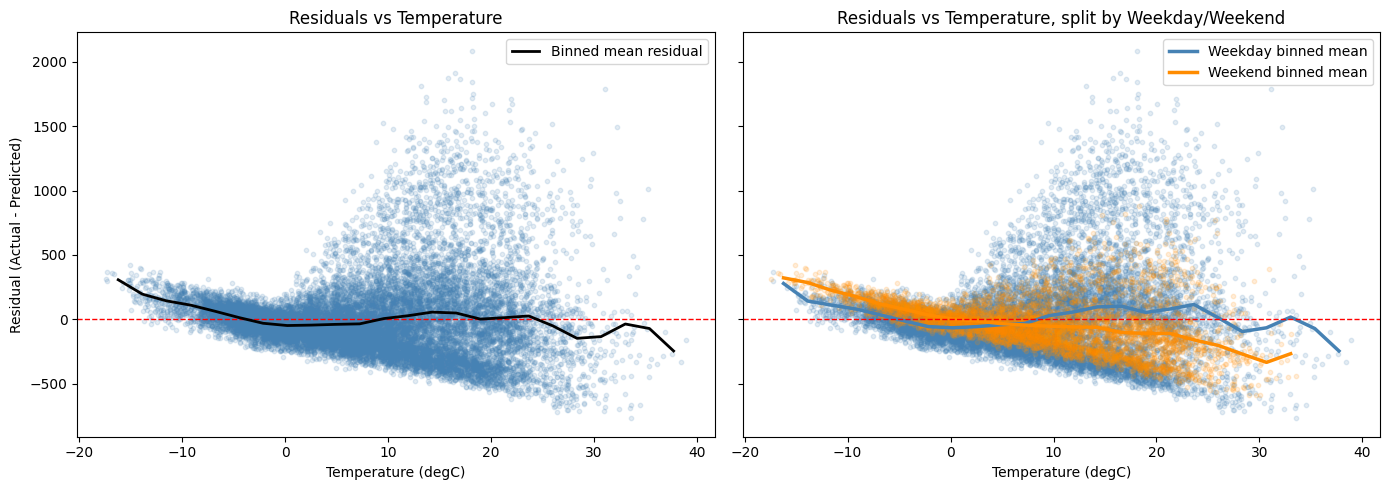

In [119]:
# Residual diagnostics for the linear baseline: in-sample residuals over the
# full training set, plotted against temperature, with and without a
# weekday/weekend split. These two plots are what motivates the quadratic
# temperature term and the temperature x is_weekend interaction in Part 3.

lr_diag = LinearRegression()
lr_diag.fit(X_train, y_train)
residuals_full = (y_train - lr_diag.predict(X_train)).values

is_weekend = train_data["dayofweek"].isin([5, 6]).values
temperature = train_data["temperature_C"].values

# bin edges shared by both panels
bins = np.linspace(temperature.min(), temperature.max(), 25)
bin_centers = (bins[:-1] + bins[1:]) / 2


def binned_mean(temp, resid, bins):
    idx = np.digitize(temp, bins)
    return np.array(
        [
            resid[idx == i].mean() if (idx == i).any() else np.nan
            for i in range(1, len(bins))
        ]
    )


fig, axs = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

# (1) Residuals vs temperature, all data
axs[0].scatter(temperature, residuals_full, alpha=0.15, s=10, color="steelblue")
axs[0].axhline(0, color="red", linestyle="--", linewidth=1)
axs[0].plot(
    bin_centers,
    binned_mean(temperature, residuals_full, bins),
    color="black",
    linewidth=2,
    label="Binned mean residual",
)
axs[0].set_xlabel("Temperature (degC)")
axs[0].set_ylabel("Residual (Actual - Predicted)")
axs[0].set_title("Residuals vs Temperature")
axs[0].legend(loc="upper right")

# (2) Residuals vs temperature, split by weekday vs weekend
for label, mask, color in [
    ("Weekday", ~is_weekend, "steelblue"),
    ("Weekend", is_weekend, "darkorange"),
]:
    axs[1].scatter(
        temperature[mask],
        residuals_full[mask],
        alpha=0.15,
        s=10,
        color=color,
    )
    axs[1].plot(
        bin_centers,
        binned_mean(temperature[mask], residuals_full[mask], bins),
        color=color,
        linewidth=2.5,
        label=f"{label} binned mean",
    )
axs[1].axhline(0, color="red", linestyle="--", linewidth=1)
axs[1].set_xlabel("Temperature (degC)")
axs[1].set_title("Residuals vs Temperature, split by Weekday/Weekend")
axs[1].legend(loc="upper right")

plt.tight_layout()
plt.show()


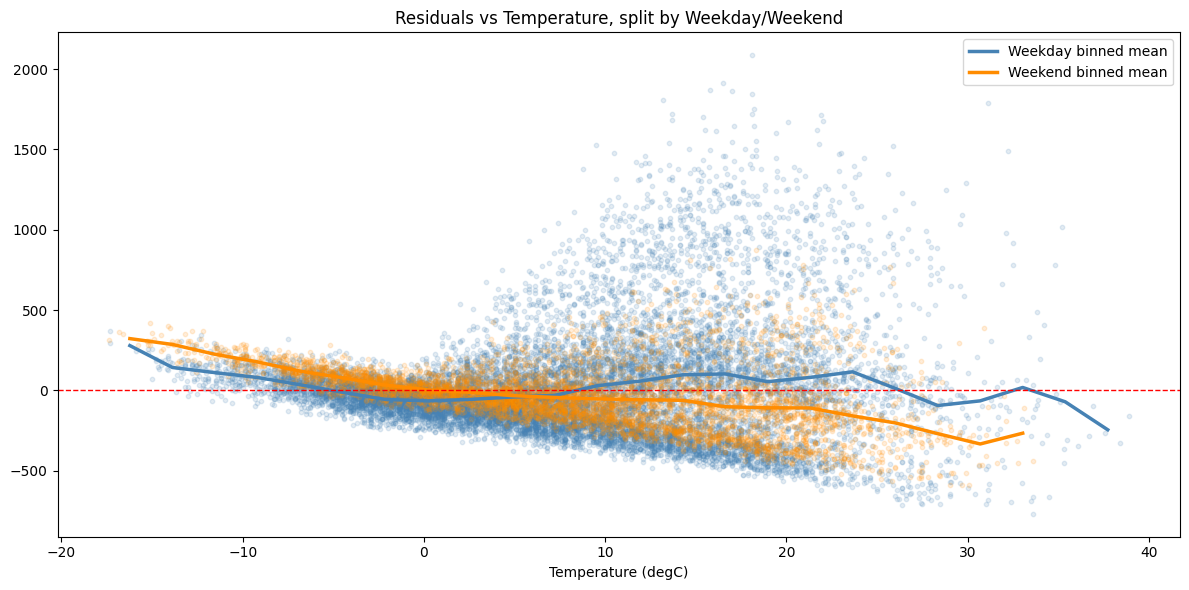

In [120]:
# Actually, plot only the residuals vs Temperature, split by the weekend, in its own canvas for easier copy-pasting
fig, ax = plt.subplots(figsize=(12, 6))
for label, mask, color in [
    ("Weekday", ~is_weekend, "steelblue"),
    ("Weekend", is_weekend, "darkorange"),
]:
    ax.scatter(
        temperature[mask],
        residuals_full[mask],
        alpha=0.15,
        s=10,
        color=color,
    )
    ax.plot(
        bin_centers,
        binned_mean(temperature[mask], residuals_full[mask], bins),
        color=color,
        linewidth=2.5,
        label=f"{label} binned mean",
    )
ax.axhline(0, color="red", linestyle="--", linewidth=1)
ax.set_xlabel("Temperature (degC)")
ax.set_title("Residuals vs Temperature, split by Weekday/Weekend")
ax.legend(loc="upper right")
# limit the cap upper y axis on 1500
plt.tight_layout()
plt.show()

In [121]:
# do the basic statistical test on the coefficients of the lienar regresssion
import statsmodels.api as sm

X_train_const = sm.add_constant(X_train)
model = sm.OLS(y_train, X_train_const).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:             bike_count   R-squared:                       0.308
Model:                            OLS   Adj. R-squared:                  0.307
Method:                 Least Squares   F-statistic:                     1268.
Date:                Tue, 05 May 2026   Prob (F-statistic):               0.00
Time:                        10:31:42   Log-Likelihood:            -1.2194e+05
No. Observations:               17129   AIC:                         2.439e+05
Df Residuals:                   17122   BIC:                         2.439e+05
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const              146.1745      8.073  

Conclusions:
* should not predict less than zero
* does not pick up weekly / hourly patterns. at all. yeah.

# Part 3 — Improved Model

**Improve your feature representation. Consider some of the transformations suggested in the section on feature engineering and your own ideas.**

Ideas:
* encode the cyclical features
* add interactions terms (likely, an hour or whether it is a holiday/not has a huge impact over impact of all features)
* Indicator variabels for weekday/weekend and holidays.

In [122]:
train_data[["hour", "dayofweek", "month"]].describe()

,hour,dayofweek,month
count,17129.00000,17129.000000,17129.000000
mean,11.50073,3.001693,6.516843
std,6.92264,1.999634,3.441387
min,0.00000,0.000000,1.000000
25%,5.00000,1.000000,4.000000
50%,11.00000,3.000000,7.000000
75%,17.00000,5.000000,10.000000
max,23.00000,6.000000,12.000000


In [123]:
train_data

,datetime,station,latitude,longitude,bike_count,temperature_C,wind_speed_ms,precipitation_mm,hour,dayofweek,month
0,2021-01-01 00:00:00,Torvegade,55.6737,12.5862,2.0,-2.8,8.7,0.0,0,4,1
1,2021-01-01 01:00:00,Torvegade,55.6737,12.5862,1.0,-3.0,9.7,0.0,1,4,1
2,2021-01-01 02:00:00,Torvegade,55.6737,12.5862,1.0,-1.8,10.2,0.0,2,4,1
3,2021-01-01 03:00:00,Torvegade,55.6737,12.5862,2.0,0.8,11.0,0.0,3,4,1
4,2021-01-01 04:00:00,Torvegade,55.6737,12.5862,3.0,0.9,11.0,0.0,4,4,1
...,...,...,...,...,...,...,...,...,...,...,...
17491,2022-12-30 19:00:00,Torvegade,55.6737,12.5862,28.0,-13.1,3.5,1.3,19,4,12
17492,2022-12-30 20:00:00,Torvegade,55.6737,12.5862,14.0,-12.8,4.7,1.2,20,4,12
17493,2022-12-30 21:00:00,Torvegade,55.6737,12.5862,16.0,-14.5,5.1,0.2,21,4,12
17495,2022-12-30 23:00:00,Torvegade,55.6737,12.5862,8.0,-14.6,4.9,0.0,23,4,12


In [124]:
# encode hour, dayofweek, month as cyclic features
train_data["hour_sin"] = np.sin(2 * np.pi * train_data["hour"] / 24)
train_data["hour_cos"] = np.cos(2 * np.pi * train_data["hour"] / 24)
train_data["dayofweek_sin"] = np.sin(2 * np.pi * train_data["dayofweek"] / 7)
train_data["dayofweek_cos"] = np.cos(2 * np.pi * train_data["dayofweek"] / 7)
train_data["month_sin"] = np.sin(2 * np.pi * train_data["month"] / 12)
train_data["month_cos"] = np.cos(2 * np.pi * train_data["month"] / 12)

features_cyclic = [
    "temperature_C",
    "wind_speed_ms",
    "precipitation_mm",
    "hour_sin",
    "hour_cos",
    "dayofweek_sin",
    "dayofweek_cos",
    "month_sin",
    "month_cos",
]

# also, encode weekends and holidays as binary features

train_data["is_weekend"] = train_data["dayofweek"].isin([5, 6]).astype(int)

train_data = pd.merge(
    train_data,
    holidays,
    left_on=train_data["datetime"].dt.date,
    right_on=holidays["date"].dt.date,
    how="left",
)

# set nans to 0 in the is_holiday columno
train_data["holiday"] = train_data["holiday"].fillna(0).astype(int)
# train_data["is_non_working_day"] = (
#     (train_data["is_weekend"] == 1) | (train_data["holiday"] == 1)
# ).astype(int)


In [125]:
train_data

,key_0,datetime,station,latitude,longitude,bike_count,temperature_C,wind_speed_ms,precipitation_mm,hour,...,month,hour_sin,hour_cos,dayofweek_sin,dayofweek_cos,month_sin,month_cos,is_weekend,date,holiday
0,2021-01-01,2021-01-01 00:00:00,Torvegade,55.6737,12.5862,2.0,-2.8,8.7,0.0,0,...,1,0.000000,1.000000,-0.433884,-0.900969,5.000000e-01,0.866025,0,2021-01-01,1
1,2021-01-01,2021-01-01 01:00:00,Torvegade,55.6737,12.5862,1.0,-3.0,9.7,0.0,1,...,1,0.258819,0.965926,-0.433884,-0.900969,5.000000e-01,0.866025,0,2021-01-01,1
2,2021-01-01,2021-01-01 02:00:00,Torvegade,55.6737,12.5862,1.0,-1.8,10.2,0.0,2,...,1,0.500000,0.866025,-0.433884,-0.900969,5.000000e-01,0.866025,0,2021-01-01,1
3,2021-01-01,2021-01-01 03:00:00,Torvegade,55.6737,12.5862,2.0,0.8,11.0,0.0,3,...,1,0.707107,0.707107,-0.433884,-0.900969,5.000000e-01,0.866025,0,2021-01-01,1
4,2021-01-01,2021-01-01 04:00:00,Torvegade,55.6737,12.5862,3.0,0.9,11.0,0.0,4,...,1,0.866025,0.500000,-0.433884,-0.900969,5.000000e-01,0.866025,0,2021-01-01,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17124,2022-12-30,2022-12-30 19:00:00,Torvegade,55.6737,12.5862,28.0,-13.1,3.5,1.3,19,...,12,-0.965926,0.258819,-0.433884,-0.900969,-2.449294e-16,1.000000,0,NaT,0
17125,2022-12-30,2022-12-30 20:00:00,Torvegade,55.6737,12.5862,14.0,-12.8,4.7,1.2,20,...,12,-0.866025,0.500000,-0.433884,-0.900969,-2.449294e-16,1.000000,0,NaT,0
17126,2022-12-30,2022-12-30 21:00:00,Torvegade,55.6737,12.5862,16.0,-14.5,5.1,0.2,21,...,12,-0.707107,0.707107,-0.433884,-0.900969,-2.449294e-16,1.000000,0,NaT,0
17127,2022-12-30,2022-12-30 23:00:00,Torvegade,55.6737,12.5862,8.0,-14.6,4.9,0.0,23,...,12,-0.258819,0.965926,-0.433884,-0.900969,-2.449294e-16,1.000000,0,NaT,0


In [126]:
train_data

,key_0,datetime,station,latitude,longitude,bike_count,temperature_C,wind_speed_ms,precipitation_mm,hour,...,month,hour_sin,hour_cos,dayofweek_sin,dayofweek_cos,month_sin,month_cos,is_weekend,date,holiday
0,2021-01-01,2021-01-01 00:00:00,Torvegade,55.6737,12.5862,2.0,-2.8,8.7,0.0,0,...,1,0.000000,1.000000,-0.433884,-0.900969,5.000000e-01,0.866025,0,2021-01-01,1
1,2021-01-01,2021-01-01 01:00:00,Torvegade,55.6737,12.5862,1.0,-3.0,9.7,0.0,1,...,1,0.258819,0.965926,-0.433884,-0.900969,5.000000e-01,0.866025,0,2021-01-01,1
2,2021-01-01,2021-01-01 02:00:00,Torvegade,55.6737,12.5862,1.0,-1.8,10.2,0.0,2,...,1,0.500000,0.866025,-0.433884,-0.900969,5.000000e-01,0.866025,0,2021-01-01,1
3,2021-01-01,2021-01-01 03:00:00,Torvegade,55.6737,12.5862,2.0,0.8,11.0,0.0,3,...,1,0.707107,0.707107,-0.433884,-0.900969,5.000000e-01,0.866025,0,2021-01-01,1
4,2021-01-01,2021-01-01 04:00:00,Torvegade,55.6737,12.5862,3.0,0.9,11.0,0.0,4,...,1,0.866025,0.500000,-0.433884,-0.900969,5.000000e-01,0.866025,0,2021-01-01,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17124,2022-12-30,2022-12-30 19:00:00,Torvegade,55.6737,12.5862,28.0,-13.1,3.5,1.3,19,...,12,-0.965926,0.258819,-0.433884,-0.900969,-2.449294e-16,1.000000,0,NaT,0
17125,2022-12-30,2022-12-30 20:00:00,Torvegade,55.6737,12.5862,14.0,-12.8,4.7,1.2,20,...,12,-0.866025,0.500000,-0.433884,-0.900969,-2.449294e-16,1.000000,0,NaT,0
17126,2022-12-30,2022-12-30 21:00:00,Torvegade,55.6737,12.5862,16.0,-14.5,5.1,0.2,21,...,12,-0.707107,0.707107,-0.433884,-0.900969,-2.449294e-16,1.000000,0,NaT,0
17127,2022-12-30,2022-12-30 23:00:00,Torvegade,55.6737,12.5862,8.0,-14.6,4.9,0.0,23,...,12,-0.258819,0.965926,-0.433884,-0.900969,-2.449294e-16,1.000000,0,NaT,0


In [127]:
# finally, let's try encoding the interaction terms between, using PolynomialFeatures, but only between temperature and cyclic features, and temperature and precipitation
features = [
    "temperature_C",
    "wind_speed_ms",
    "precipitation_mm",
    "hour_sin",
    "hour_cos",
    "dayofweek_sin",
    "dayofweek_cos",
    "month_sin",
    "month_cos",
    "is_weekend",
    "holiday",
]
# use PolynomialFeatures to get interactions with each another; max degree = 2
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=2, interaction_only=False, include_bias=False)
X_poly = poly.fit_transform(train_data[features])
feature_names = poly.get_feature_names_out(features)
X_poly_df = pd.DataFrame(X_poly, columns=feature_names)
print(len(feature_names))

77


**Apply ridge regression (or another regularization method) and select the regularization parameter using the validation set.**

In [128]:
# scale the features, and apply ridge regression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.linear_model import Ridge, Lasso
from sklearn.base import BaseEstimator, RegressorMixin
import numpy as np

# scaler = StandardScaler()
# X_scaled = scaler.fit_transform(X_poly_df)
# ridge = Ridge(alpha=1.0)
# ridge.fit(X_scaled, train_data["bike_count"])


class ClippedRidge(BaseEstimator, RegressorMixin):
    def __init__(self, alpha):
        self.alpha = alpha

    def fit(self, X, y):
        self.ridge_ = Ridge(alpha=self.alpha, fit_intercept=True)
        self.ridge_.fit(X, y)
        return self

    def predict(self, X):
        return np.clip(self.ridge_.predict(X), 0, None)


def ridge_pipeline(alpha):
    return make_pipeline(StandardScaler(), ClippedRidge(alpha=alpha))


class ClippedLasso(BaseEstimator, RegressorMixin):
    def __init__(self, alpha):
        self.alpha = alpha

    def fit(self, X, y):
        self.lasso_ = Lasso(alpha=self.alpha, fit_intercept=True, max_iter=1000)
        self.lasso_.fit(X, y)
        return self

    def predict(self, X):
        return np.clip(self.lasso_.predict(X), 0, None)


def lasso_pipeline(alpha):
    return make_pipeline(StandardScaler(), ClippedLasso(alpha=alpha))

**Compare the improved model to the baseline. Quantify the improvement and discuss which features matter most.**

In [129]:
# redo the time series cross validation with the new features and ridge regression
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error
import numpy as np

n_weeks = int((train_data["datetime"].max() - train_data["datetime"].min()).days // 7)
n_splits = max(2, n_weeks - 1)
tscv = TimeSeriesSplit(n_splits=n_splits)
rmse_list_ridge = []
preds_log_ridge = []
for fold, (train_index, val_index) in enumerate(tscv.split(X_poly_df)):
    X_tr, X_val = X_poly_df.iloc[train_index], X_poly_df.iloc[val_index]
    y_tr, y_val = (
        train_data["bike_count"].iloc[train_index],
        train_data["bike_count"].iloc[val_index],
    )
    pipeline = ridge_pipeline(alpha=0.2)
    pipeline.fit(X_tr, y_tr)
    y_pred = pipeline.predict(X_val)
    rmse = np.sqrt(mean_squared_error(y_val, y_pred))
    rmse_list_ridge.append(rmse)
    preds_log_ridge.append((y_val, y_pred, train_data.iloc[val_index]["datetime"]))
    print(f"Fold {fold + 1}: RMSE={rmse:.2f}")
print(f"\nAverage RMSE with Ridge: {np.mean(rmse_list_ridge):.2f}")

Fold 1: RMSE=70.35
Fold 2: RMSE=51.24
Fold 3: RMSE=45.67
Fold 4: RMSE=134.69
Fold 5: RMSE=126.12
Fold 6: RMSE=112.04
Fold 7: RMSE=104.84
Fold 8: RMSE=265.54
Fold 9: RMSE=159.34
Fold 10: RMSE=130.55
Fold 11: RMSE=176.09
Fold 12: RMSE=157.77
Fold 13: RMSE=214.79
Fold 14: RMSE=261.73
Fold 15: RMSE=256.41
Fold 16: RMSE=224.31
Fold 17: RMSE=279.38
Fold 18: RMSE=263.77
Fold 19: RMSE=298.54
Fold 20: RMSE=283.59
Fold 21: RMSE=316.56
Fold 22: RMSE=242.98
Fold 23: RMSE=300.01
Fold 24: RMSE=301.81
Fold 25: RMSE=257.03
Fold 26: RMSE=279.48
Fold 27: RMSE=282.76
Fold 28: RMSE=262.69
Fold 29: RMSE=293.01
Fold 30: RMSE=340.63
Fold 31: RMSE=251.76
Fold 32: RMSE=259.80
Fold 33: RMSE=247.37
Fold 34: RMSE=198.15
Fold 35: RMSE=287.49
Fold 36: RMSE=221.16
Fold 37: RMSE=255.57
Fold 38: RMSE=166.08
Fold 39: RMSE=161.73
Fold 40: RMSE=122.13
Fold 41: RMSE=137.74
Fold 42: RMSE=112.29
Fold 43: RMSE=106.10
Fold 44: RMSE=76.68
Fold 45: RMSE=78.83
Fold 46: RMSE=86.05
Fold 47: RMSE=109.10
Fold 48: RMSE=64.07
Fold 49:

In [130]:
# redo the time series cross validation with the new features and ridge regression
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error
import numpy as np

n_weeks = int((train_data["datetime"].max() - train_data["datetime"].min()).days // 7)
n_splits = max(2, n_weeks - 1)
tscv = TimeSeriesSplit(n_splits=n_splits)

lambdas = 10 ** np.linspace(8, -2, 100) / train_data["bike_count"].std()
# lambdas = [1, 10, 100, 1000, 10000, 100000]

best_la: float = 0
best_avg_rmse: float = float("inf")
for la in lambdas[::-1]:
    rmse_list = []
    print(f"Testing lambda={la:.2e}...")
    for fold, (train_index, val_index) in enumerate(tscv.split(X_poly_df)):
        X_tr, X_val = X_poly_df.iloc[train_index], X_poly_df.iloc[val_index]
        y_tr, y_val = (
            train_data["bike_count"].iloc[train_index],
            train_data["bike_count"].iloc[val_index],
        )
        pipeline = ridge_pipeline(alpha=la)
        pipeline.fit(X_tr, y_tr)
        y_pred = pipeline.predict(X_val)
        rmse = np.sqrt(mean_squared_error(y_val, y_pred))
        rmse_list.append(rmse)

        # print(f"Fold {fold + 1}: RMSE={rmse:.2f}")
    avg_rmse = np.mean(rmse_list)
    if avg_rmse < best_avg_rmse:
        best_avg_rmse = avg_rmse
        best_la = la
    print(f"Lambda={la:.2e}, Average RMSE: {avg_rmse:.2f}")

Testing lambda=2.78e-05...


Lambda=2.78e-05, Average RMSE: 193.70
Testing lambda=3.51e-05...
Lambda=3.51e-05, Average RMSE: 193.70
Testing lambda=4.43e-05...
Lambda=4.43e-05, Average RMSE: 193.70
Testing lambda=5.59e-05...
Lambda=5.59e-05, Average RMSE: 193.70
Testing lambda=7.06e-05...
Lambda=7.06e-05, Average RMSE: 193.70
Testing lambda=8.91e-05...
Lambda=8.91e-05, Average RMSE: 193.70
Testing lambda=1.12e-04...
Lambda=1.12e-04, Average RMSE: 193.70
Testing lambda=1.42e-04...
Lambda=1.42e-04, Average RMSE: 193.70
Testing lambda=1.79e-04...
Lambda=1.79e-04, Average RMSE: 193.70
Testing lambda=2.26e-04...
Lambda=2.26e-04, Average RMSE: 193.70
Testing lambda=2.85e-04...
Lambda=2.85e-04, Average RMSE: 193.71
Testing lambda=3.60e-04...
Lambda=3.60e-04, Average RMSE: 193.72
Testing lambda=4.54e-04...
Lambda=4.54e-04, Average RMSE: 193.73
Testing lambda=5.73e-04...
Lambda=5.73e-04, Average RMSE: 193.76
Testing lambda=7.23e-04...
Lambda=7.23e-04, Average RMSE: 193.81
Testing lambda=9.12e-04...
Lambda=9.12e-04, Average 

In [131]:
best_ridge_la = best_la
print(
    f"\nBest lambda for Ridge: {best_ridge_la:.2e} with Average RMSE: {best_avg_rmse:.2f}"
)


Best lambda for Ridge: 7.93e+00 with Average RMSE: 188.13


In [132]:
best_lasso_la = np.float64(0.27843740122778643)

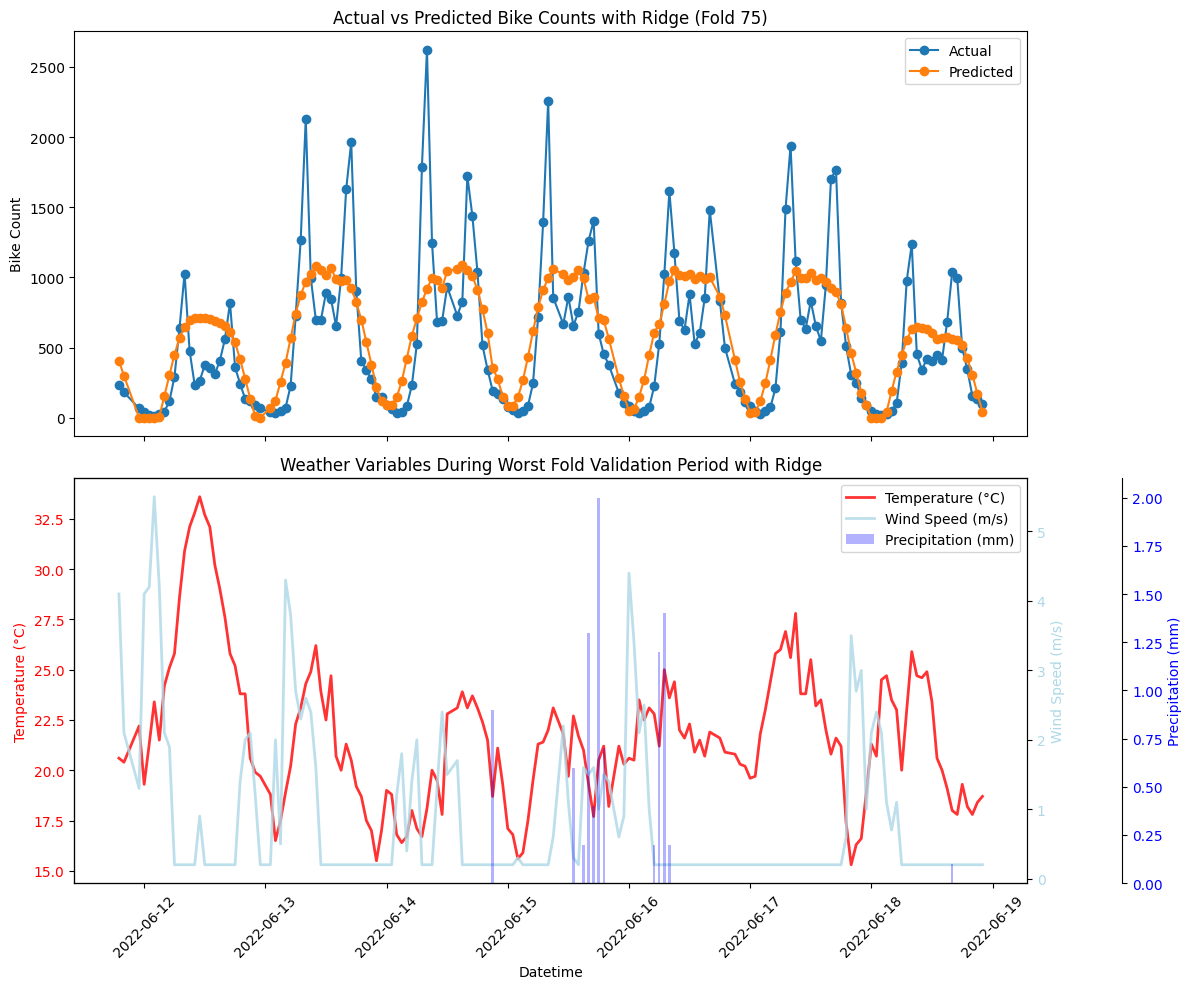

In [133]:
# again - visualise the predictions vs actuals for the worst fold
worst_fold_ridge = np.argsort(rmse_list_ridge)[-1]
train_index, val_index = list(tscv.split(X_poly_df))[worst_fold_ridge]
X_tr, X_val = X_poly_df.iloc[train_index], X_poly_df.iloc[val_index]
y_tr, y_val = (
    train_data["bike_count"].iloc[train_index],
    train_data["bike_count"].iloc[val_index],
)
pipeline = ridge_pipeline(alpha=1.0)
pipeline.fit(X_tr, y_tr)
y_pred = pipeline.predict(X_val)
val_datetimes = train_data["datetime"].iloc[val_index]

fig, axs = plt.subplots(
    2, 1, figsize=(12, 10), sharex=True, gridspec_kw={"height_ratios": [1, 1]}
)
axs[0].plot(val_datetimes, y_val, label="Actual", marker="o")
axs[0].plot(val_datetimes, y_pred, label="Predicted", marker="o")
axs[0].set_title(
    f"Actual vs Predicted Bike Counts with Ridge (Fold {worst_fold_ridge + 1})"
)
axs[0].set_xlabel("")
axs[0].set_ylabel("Bike Count")
axs[0].legend()
axs[0].tick_params(axis="x", rotation=45, labelbottom=True)
weather_val = train_weather[train_weather["datetime"].isin(val_datetimes)]
ax1 = axs[1]
ax1.plot(
    weather_val["datetime"],
    weather_val["temperature_C"],
    color="red",
    label="Temperature (°C)",
    linewidth=2,
    alpha=0.8,
)
ax1.set_ylabel("Temperature (°C)", color="red")
ax1.tick_params(axis="y", labelcolor="red")
ax2 = ax1.twinx()
ax2.plot(
    weather_val["datetime"],
    weather_val["wind_speed_ms"],
    color="lightblue",
    label="Wind Speed (m/s)",
    linewidth=2,
    alpha=0.8,
)
ax2.set_ylabel("Wind Speed (m/s)", color="lightblue")
ax2.tick_params(axis="y", labelcolor="lightblue")
ax3 = ax1.twinx()
ax3.bar(
    weather_val["datetime"],
    weather_val["precipitation_mm"],
    color="blue",
    label="Precipitation (mm)",
    width=0.02,
    alpha=0.3,
)
ax3.set_ylabel("Precipitation (mm)", color="blue")
ax3.tick_params(axis="y", labelcolor="blue")
ax3.spines["right"].set_position(("axes", 1.1))
ax3.spines["right"].set_visible(True)
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
lines3, labels3 = ax3.get_legend_handles_labels()
ax1.legend(lines1 + lines2 + lines3, labels1 + labels2 + labels3, loc="upper right")
axs[1].set_xlabel("Datetime")
axs[1].set_title("Weather Variables During Worst Fold Validation Period with Ridge")
axs[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

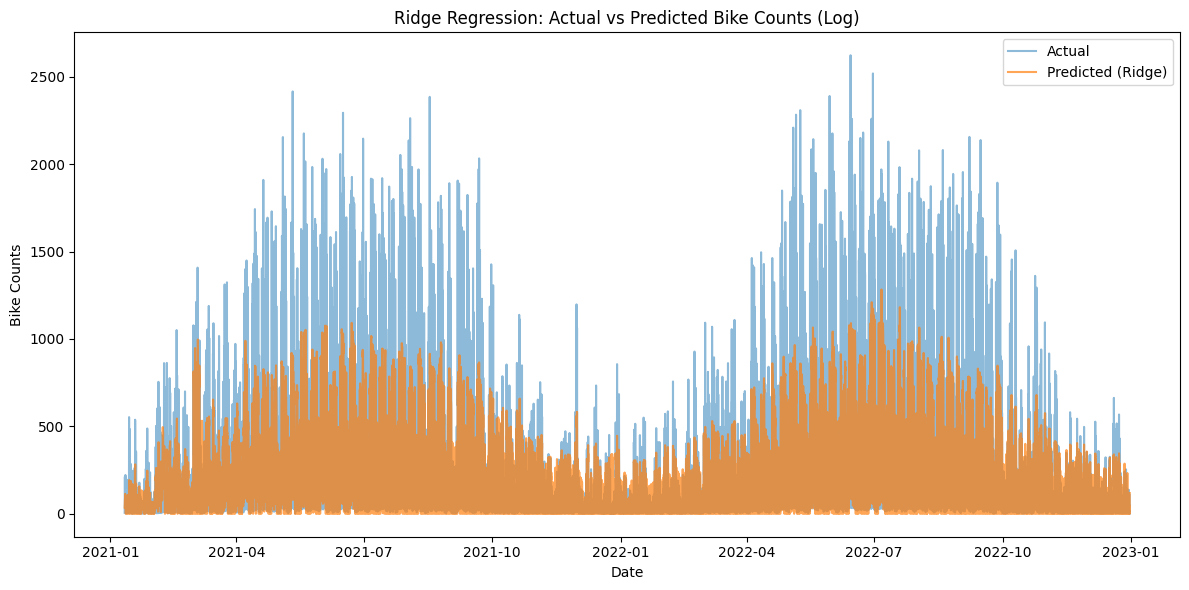

In [134]:
# create the same plot as for the linear regression (i.e. on one canvas predictes vs actual)
actuals_ridge, preds_ridge, dates_ridge = zip(*preds_log_ridge)
preds_ridge = np.concatenate(preds_ridge).tolist()
actuals_ridge = np.concatenate(actuals_ridge).tolist()
dates_ridge = np.concatenate(dates_ridge).tolist()
plt.figure(figsize=(12, 6))
plt.plot(dates_ridge, actuals_ridge, label="Actual", alpha=0.5)
plt.plot(dates_ridge, preds_ridge, label="Predicted (Ridge)", alpha=0.7)
plt.xlabel("Date")
plt.ylabel("Bike Counts")
plt.title("Ridge Regression: Actual vs Predicted Bike Counts (Log)")
plt.legend()
plt.tight_layout()
plt.show()

**Visualize the learned weights/coefficients and interpret them. Do they make sense?**

In [135]:
best_ridge_pipeline.named_steps["clippedridge"]

,alpha,np.float64(7.929997058107873)


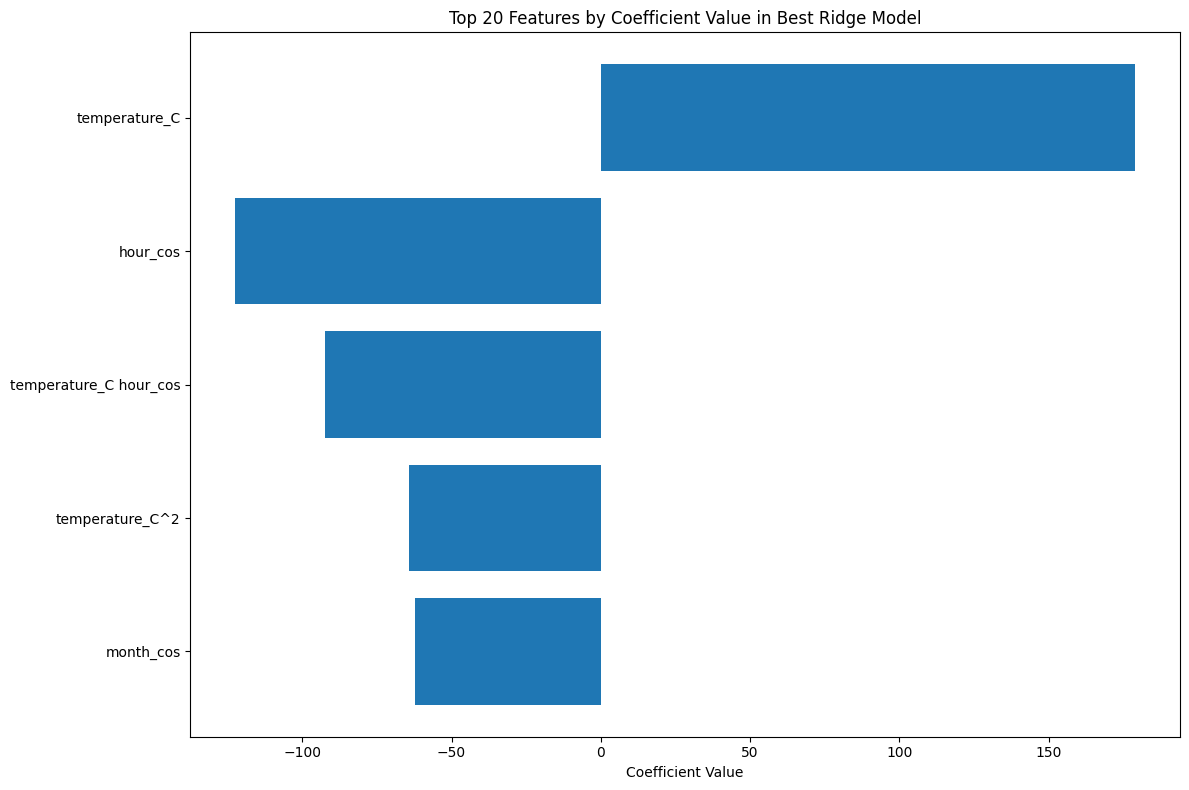

In [136]:
# visualse learnt weight/coefficients for the best ridge model
best_ridge_pipeline = ridge_pipeline(alpha=best_ridge_la)
best_ridge_pipeline.fit(X_poly_df, train_data["bike_count"])
best_ridge_model = best_ridge_pipeline.named_steps["clippedridge"].ridge_
coef_df = pd.DataFrame(
    {"feature": feature_names, "coefficient": best_ridge_model.coef_}
)
coef_df["abs_coefficient"] = coef_df["coefficient"].abs()
coef_df = coef_df.sort_values(by="abs_coefficient", ascending=False)
plt.figure(figsize=(12, 8))
plt.barh(coef_df["feature"][:5][::-1], coef_df["coefficient"][:5][::-1])
plt.xlabel("Coefficient Value")
plt.title("Top 20 Features by Coefficient Value in Best Ridge Model")
plt.tight_layout()
plt.show()

In [137]:
# actually, give me just a table for the top 5 feautes
print(coef_df[["feature", "coefficient"]].head(3))
# and for the bottom 5 features
print(coef_df[["feature", "coefficient"]].tail(3))

                   feature  coefficient
0            temperature_C   178.912764
4                 hour_cos  -122.405394
15  temperature_C hour_cos   -92.479455
                           feature  coefficient
57     dayofweek_sin dayofweek_cos    -0.497714
23  wind_speed_ms precipitation_mm    -0.429537
22                 wind_speed_ms^2    -0.425636


# Part 5 — Choose One Extension

*Choose one of the following extensions. It is fine to pick just one — going deeper on one topic is better than scratching the surface of both. It might be difficult to have a sufficient description of both within the page limit.*

# Part 4 — Generalization and Analysis

**Apply your best model to the held-out test set (year 2023). Report the performance and compare it to the validation performance.**

In [138]:
# prepare test_data for Torvegade in the same way as train_data
test_bike_counts_torv = test_bike_counts[test_bike_counts["station"] == "Torvegade"]

test_data = pd.merge(test_bike_counts_torv, test_weather, on="datetime", how="inner")
test_data = test_data.dropna(subset=["bike_count"])
test_data = pd.merge(
    test_data,
    holidays,
    left_on=test_data["datetime"].dt.date,
    right_on=holidays["date"].dt.date,
    how="left",
)
test_data["holiday"] = test_data["holiday"].fillna(0).astype(int)
test_data

,key_0,datetime,station,latitude,longitude,bike_count,temperature_C,wind_speed_ms,precipitation_mm,date,holiday
0,2023-01-01,2023-01-01 00:00:00,Torvegade,55.6737,12.5862,3.0,2.5,5.7,0.0,2023-01-01,1
1,2023-01-01,2023-01-01 01:00:00,Torvegade,55.6737,12.5862,1.0,3.4,6.7,2.5,2023-01-01,1
2,2023-01-01,2023-01-01 02:00:00,Torvegade,55.6737,12.5862,1.0,2.2,6.0,0.1,2023-01-01,1
3,2023-01-01,2023-01-01 03:00:00,Torvegade,55.6737,12.5862,1.0,4.9,7.2,1.4,2023-01-01,1
4,2023-01-01,2023-01-01 05:00:00,Torvegade,55.6737,12.5862,11.0,4.8,10.6,0.5,2023-01-01,1
...,...,...,...,...,...,...,...,...,...,...,...
8550,2023-12-30,2023-12-30 20:00:00,Torvegade,55.6737,12.5862,11.0,-3.1,9.7,0.0,NaT,0
8551,2023-12-30,2023-12-30 21:00:00,Torvegade,55.6737,12.5862,10.0,-0.9,10.4,0.1,NaT,0
8552,2023-12-30,2023-12-30 22:00:00,Torvegade,55.6737,12.5862,5.0,-2.3,12.3,0.0,NaT,0
8553,2023-12-30,2023-12-30 23:00:00,Torvegade,55.6737,12.5862,4.0,-1.7,12.1,0.0,NaT,0


In [139]:
from sklearn.base import BaseEstimator, TransformerMixin, RegressorMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import Ridge
import numpy as np


DATETIME_COL = "datetime"
WEATHER_COLS = ["temperature_C", "wind_speed_ms", "precipitation_mm"]
BINARY_COLS = ["holiday"]


class DatetimeCyclicEncoder(BaseEstimator, TransformerMixin):
    """
    Encodes a datetime column into 7 features:
      - sin/cos for hour, day-of-week, month  (6 cyclic features)
      - is_weekend derived from day-of-week   (1 binary feature)
    """

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        dt = pd.Series(X.iloc[:, 0] if hasattr(X, "iloc") else X)
        dow = dt.dt.dayofweek
        month = dt.dt.month
        hour = dt.dt.hour
        return np.column_stack(
            [
                np.sin(2 * np.pi * hour / 24),
                np.cos(2 * np.pi * hour / 24),
                np.sin(2 * np.pi * dow / 7),
                np.cos(2 * np.pi * dow / 7),
                np.sin(2 * np.pi * month / 12),
                np.cos(2 * np.pi * month / 12),
                (dow >= 5).astype(float),
            ]
        )

    def get_feature_names_out(self, input_features=None):
        return np.array(
            [
                "hour_sin",
                "hour_cos",
                "dayofweek_sin",
                "dayofweek_cos",
                "month_sin",
                "month_cos",
                "is_weekend",
            ]
        )


class ClippedRidge(BaseEstimator, RegressorMixin):
    def __init__(self, alpha=1.0):
        self.alpha = alpha

    def fit(self, X, y):
        self.ridge_ = Ridge(alpha=self.alpha, fit_intercept=True)
        self.ridge_.fit(X, y)
        return self

    def predict(self, X):
        return np.clip(self.ridge_.predict(X), 0, None)


def make_bike_pipeline(alpha=1.0):
    """
    End-to-end sklearn pipeline from a raw DataFrame to clipped bike-count predictions.

    Expected input DataFrame columns:
        datetime         – pandas datetime
        temperature_C    – numeric
        wind_speed_ms    – numeric
        precipitation_mm – numeric
        holiday          – bool / 0-1 int  (is_weekend is derived internally from datetime)
    """
    feature_transformer = ColumnTransformer(
        transformers=[
            ("cyclic", DatetimeCyclicEncoder(), [DATETIME_COL]),
            ("weather", "passthrough", WEATHER_COLS),
            ("binary", "passthrough", BINARY_COLS),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )

    return Pipeline(
        [
            ("features", feature_transformer),
            (
                "poly",
                PolynomialFeatures(
                    degree=2, interaction_only=False, include_bias=False
                ),
            ),
            ("scaler", StandardScaler()),
            ("model", ClippedRidge(alpha=alpha)),
        ]
    )


# --- usage example ---
# pipeline = make_bike_pipeline(alpha=best_ridge_la)
# pipeline.fit(train_data[WEATHER_COLS + BINARY_COLS + [DATETIME_COL]], train_data["bike_count"])
# y_pred = pipeline.predict(test_data[WEATHER_COLS + BINARY_COLS + [DATETIME_COL]])


Week  1 (2023-01-01 – 2023-01-08): RMSE = 82.43
Week  2 (2023-01-08 – 2023-01-15): RMSE = 64.43
Week  3 (2023-01-15 – 2023-01-22): RMSE = 66.55
Week  4 (2023-01-22 – 2023-01-29): RMSE = 81.53
Week  5 (2023-01-29 – 2023-02-05): RMSE = 79.18
Week  6 (2023-02-05 – 2023-02-12): RMSE = 88.97
Week  7 (2023-02-12 – 2023-02-19): RMSE = 87.57
Week  8 (2023-02-19 – 2023-02-26): RMSE = 85.83
Week  9 (2023-02-26 – 2023-03-05): RMSE = 88.06
Week 10 (2023-03-05 – 2023-03-12): RMSE = 118.13
Week 11 (2023-03-12 – 2023-03-19): RMSE = 198.35
Week 12 (2023-03-19 – 2023-03-26): RMSE = 153.34
Week 13 (2023-03-26 – 2023-04-02): RMSE = 170.58
Week 14 (2023-04-02 – 2023-04-09): RMSE = 221.46
Week 15 (2023-04-09 – 2023-04-16): RMSE = 179.29
Week 16 (2023-04-16 – 2023-04-23): RMSE = 207.19
Week 17 (2023-04-23 – 2023-04-30): RMSE = 200.86
Week 18 (2023-04-30 – 2023-05-07): RMSE = 274.32
Week 19 (2023-05-07 – 2023-05-14): RMSE = 281.49
Week 20 (2023-05-14 – 2023-05-21): RMSE = 254.07
Week 21 (2023-05-21 – 2023-05

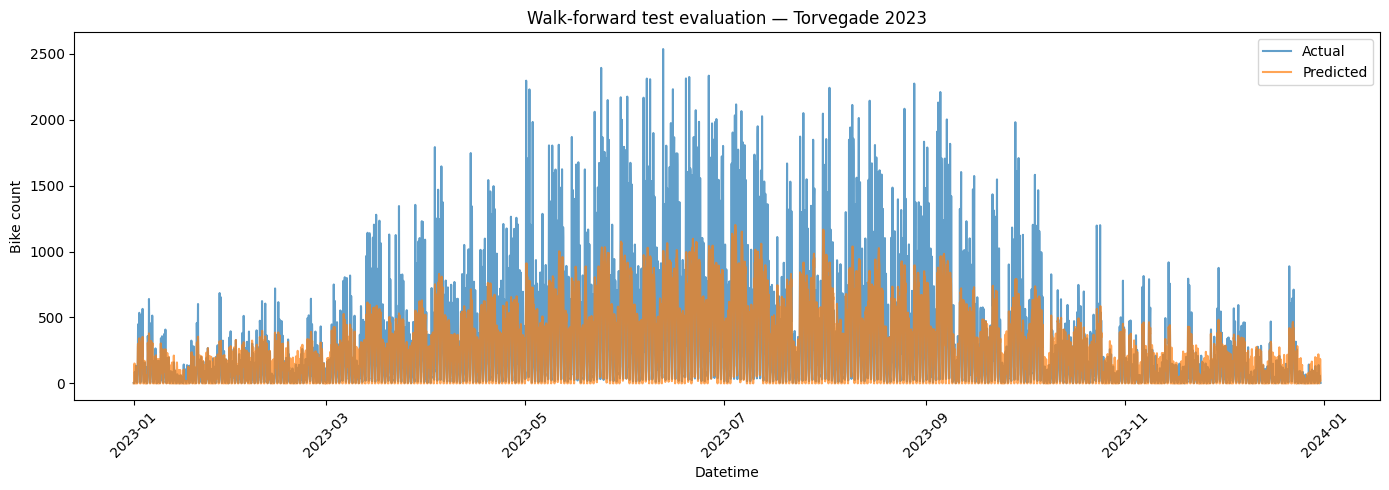

In [140]:
from sklearn.metrics import mean_squared_error
import numpy as np

INPUT_COLS = WEATHER_COLS + BINARY_COLS + [DATETIME_COL]

# generate weekly start timestamps covering the entire test set
test_start = test_data["datetime"].min().normalize()
n_test_weeks = int(np.ceil((test_data["datetime"].max() - test_start).days / 7))

rolling_train = train_data.copy()
rmse_list_test = []
preds_log_test = []

for week_i in range(n_test_weeks):
    week_start = test_start + pd.Timedelta(weeks=week_i)
    week_end = week_start + pd.Timedelta(weeks=1)

    mask = (test_data["datetime"] >= week_start) & (test_data["datetime"] < week_end)
    X_week = test_data.loc[mask, INPUT_COLS]
    y_week = test_data.loc[mask, "bike_count"]

    if len(X_week) == 0:
        continue

    pipeline = make_bike_pipeline(alpha=best_ridge_la)
    pipeline.fit(rolling_train[INPUT_COLS], rolling_train["bike_count"])
    y_pred = pipeline.predict(X_week)

    rmse = np.sqrt(mean_squared_error(y_week, y_pred))
    rmse_list_test.append(rmse)
    preds_log_test.append(
        (y_week.values, y_pred, test_data.loc[mask, "datetime"].values)
    )
    print(
        f"Week {week_i + 1:2d} ({week_start.date()} – {week_end.date()}): RMSE = {rmse:.2f}"
    )

    # grow training set with this week before the next iteration
    rolling_train = pd.concat([rolling_train, test_data.loc[mask]], ignore_index=True)

print(f"\nAverage Test RMSE: {np.mean(rmse_list_test):.2f}")
print(f"Validation RMSE (best ridge):  {best_avg_rmse:.2f}")

# --- plot actuals vs predictions across the whole test horizon ---
actuals_all = np.concatenate([a for a, _, _ in preds_log_test])
preds_all = np.concatenate([p for _, p, _ in preds_log_test])
dates_all = np.concatenate([d for _, _, d in preds_log_test])

plt.figure(figsize=(14, 5))
plt.plot(dates_all, actuals_all, label="Actual", alpha=0.7)
plt.plot(dates_all, preds_all, label="Predicted", alpha=0.7)
plt.title("Walk-forward test evaluation — Torvegade 2023")
plt.xlabel("Datetime")
plt.ylabel("Bike count")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


**Train and evaluate the model for all six stations. Can one model work for all stations, or do different stations need different models? Visualize and discuss.**

In [141]:
def prepare_data(bike_counts_df, weather_df, holidays_df):
    """Merge bike counts with weather, drop missing targets, attach holiday flag."""
    data = pd.merge(bike_counts_df, weather_df, on="datetime", how="inner")
    data = data.dropna(subset=["bike_count"])
    data = pd.merge(
        data,
        holidays_df,
        left_on=data["datetime"].dt.date,
        right_on=holidays_df["date"].dt.date,
        how="left",
    )
    data["holiday"] = data["holiday"].fillna(0).astype(int)
    return data.reset_index(drop=True)


# concatenate all stations into one dataset, sorted by datetime
train_data_all = (
    pd.concat(
        [
            prepare_data(
                train_bike_counts[train_bike_counts["station"] == s],
                train_weather,
                holidays,
            )
            for s in stations["station"]
        ],
        ignore_index=True,
    )
    .sort_values("datetime")
    .reset_index(drop=True)
)

test_data_all = (
    pd.concat(
        [
            prepare_data(
                test_bike_counts[test_bike_counts["station"] == s],
                test_weather,
                holidays,
            )
            for s in stations["station"]
        ],
        ignore_index=True,
    )
    .sort_values("datetime")
    .reset_index(drop=True)
)

print(f"Combined train rows: {len(train_data_all)}")
print(f"Combined test  rows: {len(test_data_all)}")

Combined train rows: 102861
Combined test  rows: 51417


In [142]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error

n_weeks = int(
    (train_data_all["datetime"].max() - train_data_all["datetime"].min()).days // 7
)
n_splits = max(2, n_weeks - 1)
tscv = TimeSeriesSplit(n_splits=n_splits)

lambdas = 10 ** np.linspace(8, -2, 100) / train_data_all["bike_count"].std()

best_la_all = lambdas[0]
best_avg_rmse_all = float("inf")

for la in lambdas[::-1]:
    fold_rmses = []
    for train_idx, val_idx in tscv.split(train_data_all):
        pipe = make_bike_pipeline(alpha=la)
        pipe.fit(
            train_data_all.iloc[train_idx][INPUT_COLS],
            train_data_all.iloc[train_idx]["bike_count"],
        )
        y_pred = pipe.predict(train_data_all.iloc[val_idx][INPUT_COLS])
        fold_rmses.append(
            np.sqrt(
                mean_squared_error(train_data_all.iloc[val_idx]["bike_count"], y_pred)
            )
        )
        print(f"λ={la:.2e}, Fold RMSE={fold_rmses[-1]:.2f}")
    avg_rmse = np.mean(fold_rmses)
    if avg_rmse < best_avg_rmse_all:
        best_avg_rmse_all = avg_rmse
        best_la_all = la

print(f"Best α = {best_la_all:.2e}   val RMSE = {best_avg_rmse_all:.2f}")

λ=2.36e-05, Fold RMSE=144.85
λ=2.36e-05, Fold RMSE=73.53
λ=2.36e-05, Fold RMSE=84.68
λ=2.36e-05, Fold RMSE=102.58
λ=2.36e-05, Fold RMSE=171.44
λ=2.36e-05, Fold RMSE=188.39
λ=2.36e-05, Fold RMSE=108.55
λ=2.36e-05, Fold RMSE=267.46
λ=2.36e-05, Fold RMSE=309.21
λ=2.36e-05, Fold RMSE=212.90
λ=2.36e-05, Fold RMSE=239.74
λ=2.36e-05, Fold RMSE=192.22
λ=2.36e-05, Fold RMSE=278.59
λ=2.36e-05, Fold RMSE=336.10
λ=2.36e-05, Fold RMSE=341.03
λ=2.36e-05, Fold RMSE=340.66
λ=2.36e-05, Fold RMSE=380.90
λ=2.36e-05, Fold RMSE=331.06
λ=2.36e-05, Fold RMSE=436.53
λ=2.36e-05, Fold RMSE=379.18
λ=2.36e-05, Fold RMSE=427.83
λ=2.36e-05, Fold RMSE=375.53
λ=2.36e-05, Fold RMSE=432.31
λ=2.36e-05, Fold RMSE=445.10
λ=2.36e-05, Fold RMSE=358.39
λ=2.36e-05, Fold RMSE=404.04
λ=2.36e-05, Fold RMSE=380.98
λ=2.36e-05, Fold RMSE=358.25
λ=2.36e-05, Fold RMSE=398.81
λ=2.36e-05, Fold RMSE=442.37
λ=2.36e-05, Fold RMSE=378.10
λ=2.36e-05, Fold RMSE=363.26
λ=2.36e-05, Fold RMSE=402.39
λ=2.36e-05, Fold RMSE=268.53
λ=2.36e-05, Fold

KeyboardInterrupt: 

In [ ]:
test_start = test_data_all["datetime"].min().normalize()
n_test_weeks = int(np.ceil((test_data_all["datetime"].max() - test_start).days / 7))

rolling_train = train_data_all.copy()
fold_rmses_test = []

for week_i in range(n_test_weeks):
    week_start = test_start + pd.Timedelta(weeks=week_i)
    week_end = week_start + pd.Timedelta(weeks=1)
    mask = (test_data_all["datetime"] >= week_start) & (
        test_data_all["datetime"] < week_end
    )
    X_week = test_data_all.loc[mask, INPUT_COLS]
    y_week = test_data_all.loc[mask, "bike_count"]
    if len(X_week) == 0:
        continue

    pipe = make_bike_pipeline(alpha=best_la_all)
    pipe.fit(rolling_train[INPUT_COLS], rolling_train["bike_count"])
    fold_rmses_test.append(np.sqrt(mean_squared_error(y_week, pipe.predict(X_week))))
    rolling_train = pd.concat(
        [rolling_train, test_data_all.loc[mask]], ignore_index=True
    )

test_rmse_all = np.mean(fold_rmses_test)
print(f"Val RMSE  (all stations): {best_avg_rmse_all:.2f}")
print(f"Test RMSE (all stations): {test_rmse_all:.2f}")
print(f"Δ: {test_rmse_all - best_avg_rmse_all:+.2f}")

Val RMSE  (all stations): 260.77
Test RMSE (all stations): 262.69
Δ: +1.92


**Investigate if a model trained on one station transfers to another (i.e. train on Dronning Louises Bro, predict Torvegade). What does this tell you about the stations?**

In [ ]:
# ── 1. find best alpha trained only on Dronning Louises Bro ──────────────────
SOURCE_STATION = "Dronning_Louises_Bro"
TARGET_STATION = "Torvegade"

train_source = prepare_data(
    train_bike_counts[train_bike_counts["station"] == SOURCE_STATION],
    train_weather,
    holidays,
)

n_weeks = int(
    (train_source["datetime"].max() - train_source["datetime"].min()).days // 7
)
n_splits = max(2, n_weeks - 1)
tscv = TimeSeriesSplit(n_splits=n_splits)
lambdas = 10 ** np.linspace(8, -2, 100) / train_source["bike_count"].std()

best_la_transfer = lambdas[0]
best_avg_rmse_transfer = float("inf")

for la in lambdas[::-1]:
    fold_rmses = []
    for train_idx, val_idx in tscv.split(train_source):
        pipe = make_bike_pipeline(alpha=la)
        pipe.fit(
            train_source.iloc[train_idx][INPUT_COLS],
            train_source.iloc[train_idx]["bike_count"],
        )
        y_pred = pipe.predict(train_source.iloc[val_idx][INPUT_COLS])
        fold_rmses.append(
            np.sqrt(
                mean_squared_error(train_source.iloc[val_idx]["bike_count"], y_pred)
            )
        )
    avg_rmse = np.mean(fold_rmses)
    if avg_rmse < best_avg_rmse_transfer:
        best_avg_rmse_transfer = avg_rmse
        best_la_transfer = la

print(
    f"{SOURCE_STATION} — best α = {best_la_transfer:.2e},  val RMSE = {best_avg_rmse_transfer:.2f}"
)

# ── 2. walk-forward test on Torvegade using the model trained on source ───────
test_target = prepare_data(
    test_bike_counts[test_bike_counts["station"] == TARGET_STATION],
    test_weather,
    holidays,
)

test_start = test_target["datetime"].min().normalize()
n_test_weeks = int(np.ceil((test_target["datetime"].max() - test_start).days / 7))

# rolling train starts from source station only; grows with Torvegade test weeks
rolling_train = train_source.copy()
fold_rmses_transfer = []

for week_i in range(n_test_weeks):
    week_start = test_start + pd.Timedelta(weeks=week_i)
    week_end = week_start + pd.Timedelta(weeks=1)
    mask = (test_target["datetime"] >= week_start) & (
        test_target["datetime"] < week_end
    )
    X_week = test_target.loc[mask, INPUT_COLS]
    y_week = test_target.loc[mask, "bike_count"]
    if len(X_week) == 0:
        continue

    pipe = make_bike_pipeline(alpha=best_la_transfer)
    pipe.fit(rolling_train[INPUT_COLS], rolling_train["bike_count"])
    fold_rmses_transfer.append(
        np.sqrt(mean_squared_error(y_week, pipe.predict(X_week)))
    )
    rolling_train = pd.concat([rolling_train, test_target.loc[mask]], ignore_index=True)

test_rmse_transfer = np.mean(fold_rmses_transfer)

# ── 3. compare against Torvegade trained on its own data ─────────────────────
# (reuse best_ridge_la and best_avg_rmse from the single-station Torvegade search)
print(f"\nTransfer {SOURCE_STATION} → {TARGET_STATION}")
print(f"  val RMSE  ({SOURCE_STATION}): {best_avg_rmse_transfer:.2f}")
print(f"  test RMSE (on {TARGET_STATION}):  {test_rmse_transfer:.2f}")
print(f"\nOwn model on {TARGET_STATION}")
print(f"  val RMSE:  {best_avg_rmse:.2f}")
print(f"  test RMSE: {np.mean(rmse_list_test):.2f}")

Dronning_Louises_Bro — best α = 1.78e+01,  val RMSE = 338.44

Transfer Dronning_Louises_Bro → Torvegade
  val RMSE  (Dronning_Louises_Bro): 338.44
  test RMSE (on Torvegade):  296.04

Own model on Torvegade
  val RMSE:  188.13
  test RMSE: 187.56


## 5.B — Temporal Prediction

Instead of predicting traffic from weather alone, investigate whether including past traffic counts (e.g. the count 1 hour ago, 24 hours ago, or 1 week ago) improves prediction. This turns the problem into a time series forecasting task. Discuss the practical implications. For example, the weather model only needs a weather forecast, while the temporal model needs recent real-time data.

In [143]:
LAG_COL = "bike_count_lag_1w"
INPUT_COLS_LAG = WEATHER_COLS + [LAG_COL] + BINARY_COLS + [DATETIME_COL]


def make_bike_pipeline_lag(alpha=1.0):
    """Same pipeline as make_bike_pipeline but with an extra numeric lag feature."""
    feature_transformer = ColumnTransformer(
        transformers=[
            ("cyclic", DatetimeCyclicEncoder(), [DATETIME_COL]),
            ("numeric", "passthrough", WEATHER_COLS + [LAG_COL]),
            ("binary", "passthrough", BINARY_COLS),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )
    return Pipeline(
        [
            ("features", feature_transformer),
            (
                "poly",
                PolynomialFeatures(
                    degree=2, interaction_only=False, include_bias=False
                ),
            ),
            ("scaler", StandardScaler()),
            ("model", ClippedRidge(alpha=alpha)),
        ]
    )


# build Torvegade dataset spanning the full date range, interpolate bike_count,
# then add the 1-week lag before splitting — so lag values are always available
torv_full = (
    pd.merge(
        bike_counts[bike_counts["station"] == "Torvegade"],
        weather,
        on="datetime",
        how="inner",
    )
    .sort_values("datetime")
    .reset_index(drop=True)
)

torv_full["bike_count"] = torv_full["bike_count"].interpolate(method="linear")

torv_full = pd.merge(
    torv_full,
    holidays,
    left_on=torv_full["datetime"].dt.date,
    right_on=holidays["date"].dt.date,
    how="left",
)
torv_full["holiday"] = torv_full["holiday"].fillna(0).astype(int)

# 168 rows = 168 hours = 1 week (hourly data)
torv_full[LAG_COL] = torv_full["bike_count"].shift(168)

train_data_lag = (
    torv_full[
        (torv_full["datetime"] >= train_start_date)
        & (torv_full["datetime"] <= train_end_date)
    ]
    .dropna(subset=[LAG_COL])
    .reset_index(drop=True)
)

test_data_lag = torv_full[
    (torv_full["datetime"] >= test_start_date)
    & (torv_full["datetime"] <= test_end_date)
].reset_index(drop=True)

print(f"train rows: {len(train_data_lag)},  test rows: {len(test_data_lag)}")
print(f"lag NaNs in test: {test_data_lag[LAG_COL].isna().sum()}")  # should be 0

train rows: 17329,  test rows: 8737
lag NaNs in test: 0


In [144]:
n_weeks = int(
    (train_data_lag["datetime"].max() - train_data_lag["datetime"].min()).days // 7
)
n_splits = max(2, n_weeks - 1)
tscv = TimeSeriesSplit(n_splits=n_splits)
lambdas = 10 ** np.linspace(8, -2, 100) / train_data_lag["bike_count"].std()

best_la_lag = lambdas[0]
best_avg_rmse_lag = float("inf")

for la in lambdas[::-1]:
    fold_rmses = []
    for train_idx, val_idx in tscv.split(train_data_lag):
        pipe = make_bike_pipeline_lag(alpha=la)
        pipe.fit(
            train_data_lag.iloc[train_idx][INPUT_COLS_LAG],
            train_data_lag.iloc[train_idx]["bike_count"],
        )
        y_pred = pipe.predict(train_data_lag.iloc[val_idx][INPUT_COLS_LAG])
        fold_rmses.append(
            np.sqrt(
                mean_squared_error(train_data_lag.iloc[val_idx]["bike_count"], y_pred)
            )
        )
    avg_rmse = np.mean(fold_rmses)
    if avg_rmse < best_avg_rmse_lag:
        best_avg_rmse_lag = avg_rmse
        best_la_lag = la

print(f"Best α = {best_la_lag:.2e}   val RMSE (lag model) = {best_avg_rmse_lag:.2f}")


Best α = 1.63e+02   val RMSE (lag model) = 131.34


                                  Val RMSE   Test RMSE
-------------------------------------------------------
Lag model (1-week lag)              131.34      127.88
No-lag model                        188.13      187.56


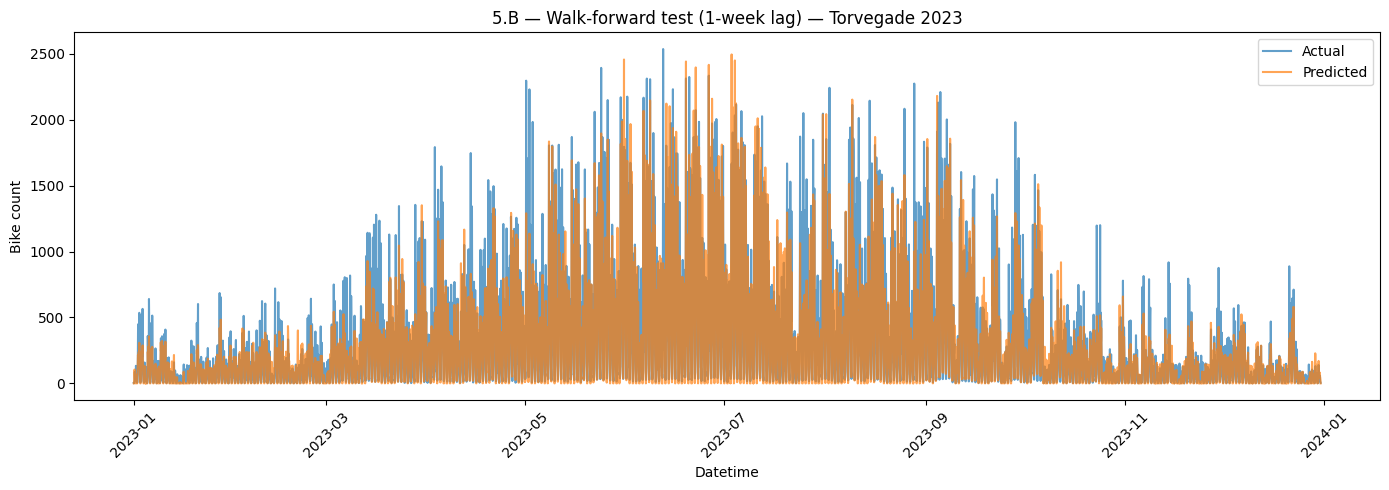

In [ ]:
test_start = test_data_lag["datetime"].min().normalize()
n_test_weeks = int(np.ceil((test_data_lag["datetime"].max() - test_start).days / 7))

rolling_train = train_data_lag.copy()
fold_rmses_lag = []
preds_log_lag = []

for week_i in range(n_test_weeks):
    week_start = test_start + pd.Timedelta(weeks=week_i)
    week_end = week_start + pd.Timedelta(weeks=1)
    mask = (test_data_lag["datetime"] >= week_start) & (
        test_data_lag["datetime"] < week_end
    )
    X_week = test_data_lag.loc[mask, INPUT_COLS_LAG]
    y_week = test_data_lag.loc[mask, "bike_count"]
    if len(X_week) == 0:
        continue

    pipe = make_bike_pipeline_lag(alpha=best_la_lag)
    pipe.fit(rolling_train[INPUT_COLS_LAG], rolling_train["bike_count"])
    # print amount of the features used in the lag model
    y_pred = pipe.predict(X_week)

    fold_rmses_lag.append(np.sqrt(mean_squared_error(y_week, y_pred)))
    preds_log_lag.append(
        (y_week.values, y_pred, test_data_lag.loc[mask, "datetime"].values)
    )
    rolling_train = pd.concat(
        [rolling_train, test_data_lag.loc[mask]], ignore_index=True
    )

test_rmse_lag = np.mean(fold_rmses_lag)

print(f"{'':30s}  {'Val RMSE':>10s}  {'Test RMSE':>10s}")
print("-" * 55)
print(
    f"{'Lag model (1-week lag)':30s}  {best_avg_rmse_lag:>10.2f}  {test_rmse_lag:>10.2f}"
)
print(f"{'No-lag model':30s}  {best_avg_rmse:>10.2f}  {np.mean(rmse_list_test):>10.2f}")

# plot
actuals_all = np.concatenate([a for a, _, _ in preds_log_lag])
preds_all = np.concatenate([p for _, p, _ in preds_log_lag])
dates_all = np.concatenate([d for _, _, d in preds_log_lag])

plt.figure(figsize=(14, 5))
plt.plot(dates_all, actuals_all, label="Actual", alpha=0.7)
plt.plot(dates_all, preds_all, label="Predicted", alpha=0.7)
plt.title("5.B — Walk-forward test (1-week lag) — Torvegade 2023")
plt.xlabel("Datetime")
plt.ylabel("Bike count")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [ ]:
# print number of the features used in the lag model
pipe.named_steps["model"].ridge_.coef_.shape
# print intercep

np.float64(279.51442223646717)

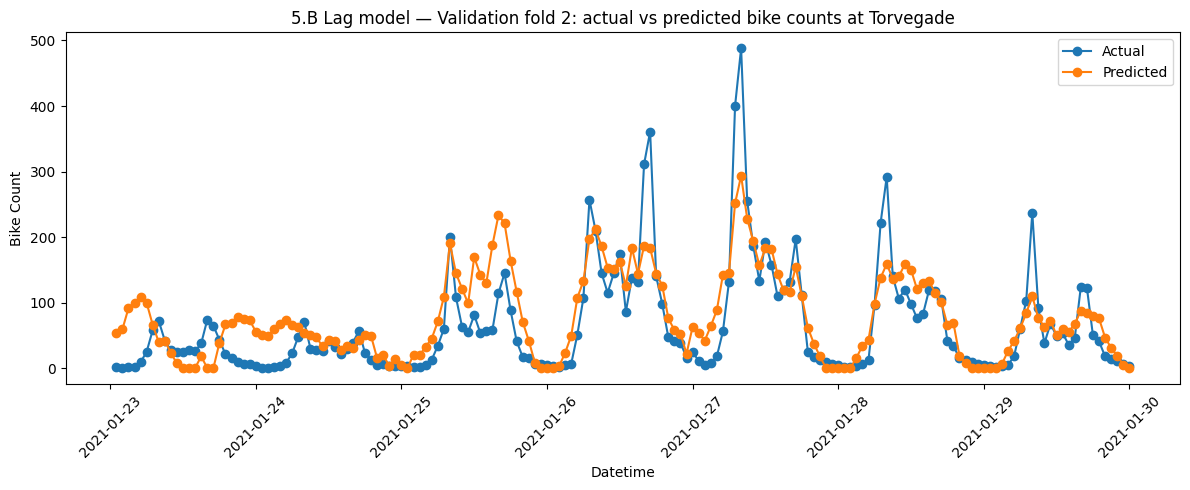

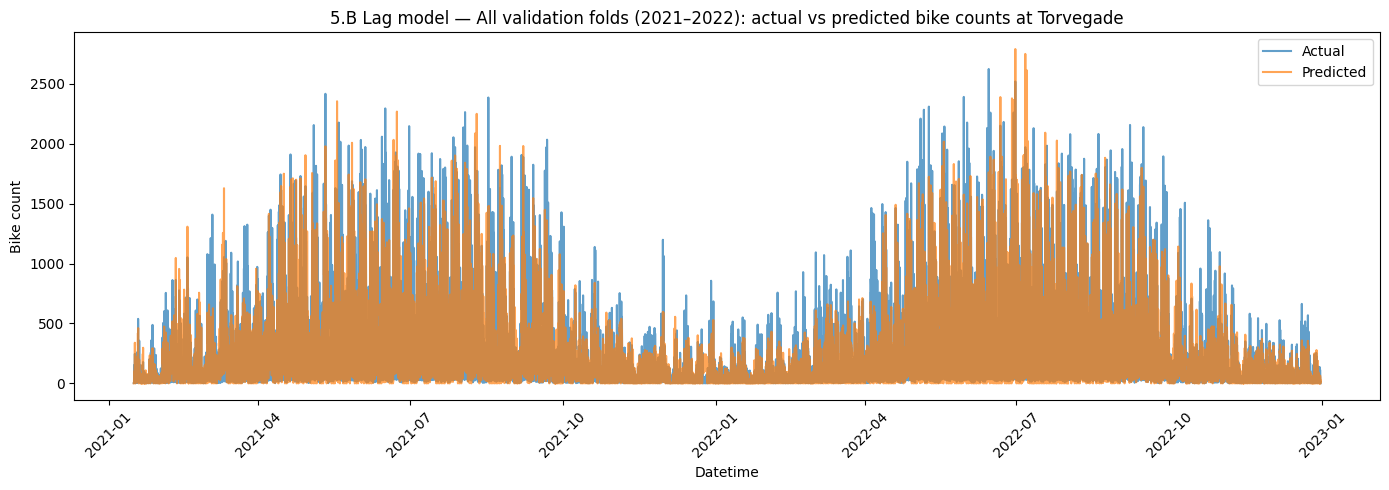

In [167]:
# re-run CV with best_la_lag to collect per-fold validation predictions
n_weeks_lag = int(
    (train_data_lag["datetime"].max() - train_data_lag["datetime"].min()).days // 7
)
tscv_lag = TimeSeriesSplit(n_splits=max(2, n_weeks_lag - 1))

val_preds_all_folds = []  # (actuals, predictions, datetimes) per fold

for train_idx, val_idx in tscv_lag.split(train_data_lag):
    pipe = make_bike_pipeline_lag(alpha=best_la_lag)
    pipe.fit(
        train_data_lag.iloc[train_idx][INPUT_COLS_LAG],
        train_data_lag.iloc[train_idx]["bike_count"],
    )
    y_pred = pipe.predict(train_data_lag.iloc[val_idx][INPUT_COLS_LAG])
    val_preds_all_folds.append(
        (
            train_data_lag.iloc[val_idx]["bike_count"].values,
            y_pred,
            train_data_lag.iloc[val_idx]["datetime"].values,
        )
    )

# ── Figure 1: fold 3 ─────────────────────────────────────────────────────────
FOLD = 1
actuals_f3, preds_f3, dates_f3 = val_preds_all_folds[FOLD]

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(dates_f3, actuals_f3, label="Actual", marker="o")
ax.plot(dates_f3, preds_f3, label="Predicted", marker="o")
ax.set_title(
    f"5.B Lag model — Validation fold {FOLD + 1}: "
    f"actual vs predicted bike counts at Torvegade"
)
ax.set_xlabel("Datetime")
ax.set_ylabel("Bike Count")
ax.legend()
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

# ── Figure 2: all validation folds concatenated (full 2-year span) ────────────
actuals_val = np.concatenate([a for a, _, _ in val_preds_all_folds])
preds_val = np.concatenate([p for _, p, _ in val_preds_all_folds])
dates_val = np.concatenate([d for _, _, d in val_preds_all_folds])
order = np.argsort(dates_val)

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(dates_val[order], actuals_val[order], label="Actual", alpha=0.7)
ax.plot(dates_val[order], preds_val[order], label="Predicted", alpha=0.7)
ax.set_title(
    "5.B Lag model — All validation folds (2021–2022): "
    "actual vs predicted bike counts at Torvegade"
)
ax.set_xlabel("Datetime")
ax.set_ylabel("Bike count")
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
